# Tugas Terstruktur dan Milestone Proyek UAS — Pertemuan 11
## Evaluasi Klasifikasi Risiko *Dropout* Mahasiswa Pasca-Semester Pertama, Kalibrasi Probabilitas, dan Pemilihan Ambang Keputusan Berbasis Biaya pada Dataset Pendidikan Tinggi Portugal (UCI #697)

---

### Identitas Mahasiswa dan Informasi Pengumpulan
| Komponen | Keterangan |
| :--- | :--- |
| **Nama Mahasiswa** | Fadli Hifziansyah |
| **NIM** | `241730042` |
| **Kelas** | `5 INF B` |
| **Mata Kuliah** | Pembelajaran Mesin (*Machine Learning*) — Pertemuan 11 |
| **Dosen Pengampu** | Bapak Ahmad Tabrani |
| **Sumber Dataset Empiris** | *Predict Students' Dropout and Academic Success* — UCI Machine Learning Repository ID #697 (DOI Resmi Dataset: `10.24432/C5MC89`; Artikel Deskripsi Dataset: Realinho et al., 2022, DOI: `10.3390/data7110146`; Lisensi `CC BY 4.0`; berkas lokal `dataset-asli.csv`) |
| **Nama Berkas Pengumpulan** | `241730042_Fadli_Hifziansyah_P11_TugasML.ipynb` |

---

### Peta Kesesuaian Lengkap terhadap Instruksi Tugas Dosen (11 Langkah, 5 Latihan Analitis, & 8 Luaran)
| Instruksi Tugas Dosen | Lokasi Pengerjaan di Notebook & Luaran Pendamping |
| :--- | :--- |
| **Langkah 1:** Konteks kasus, unit analisis, kelas positif, dan keputusan yang dibantu | **Bagian 1** & **Bagian 2.5** |
| **Langkah 2:** Hitung *confusion matrix* & metrik pada *threshold* `0,5` lalu bandingkan dengan `0,3` dan `0,7` (data validasi) | **Bagian 5.2** + `tabel_luaran_p11/01_tabel_tiga_threshold_wajib_validasi.csv` + `visualisasi_p11/02_tiga_confusion_matrix_validasi.png` |
| **Langkah 3:** Sajikan perbandingan *Precision*, *Recall*, *Specificity*, dan *F1-Score* | **Bagian 5.2** (Tabel & Interpretasi) & **Bagian 6.3–6.4** (Tabel Trade-Off & Kurva Lintas Threshold) |
| **Langkah 4 & 5:** Hitung `ROC-AUC` & `PR-AUC` (`AP` vs. *Trapezoidal*), plot *ROC Curve* dan *Precision–Recall Curve* | **Bagian 5.1** & **Bagian 5.3** + `visualisasi_p11/03_roc_pr_reliability_validasi.png` |
| **Langkah 6:** Periksa kualitas kalibrasi probabilitas model (*Brier Score*, `ECE`, per-*bin*, *Reliability Diagram*) | **Bagian 5.1** & **Bagian 5.3** |
| **Langkah 7:** Susun matriks biaya *False Positive* dan *False Negative* | **Bagian 6.1** & **Bagian 6.3** + `tabel_luaran_p11/03_matriks_biaya_2x2_dan_sensitivitas_rasio.csv` |
| **Langkah 8:** Pilih *threshold* operasional (biaya FP/FN, prevalensi kelas, kapasitas tindak lanjut) & jelaskan alasannya | **Bagian 6.2–6.5** (Eksak vs. Grid `0,01`) & Evaluasi Akhir Satu Kali *Test Set* di **Bagian 7.2** |
| **Langkah 9:** Analisis minimal tiga kesalahan prediksi yang penting | **Bagian 7.1** (4 kasus observasi nyata di *Validation Set*: Fakta, Interpretasi, Hipotesis) |
| **Langkah 10:** Proposal singkat artikel UAS (pertanyaan riset, dataset, *baseline*, model, metrik, rencana eksperimen) | **Bagian 8.1** + `PROPOSAL_DAN_REKOMENDASI_UAS_P11.md` |
| **Langkah 11:** Calon jurnal SINTA 4 & bukti verifikasi awal | **Bagian 8.2** + folder `bukti_sinta/` + `tabel_luaran_p11/06_verifikasi_calon_jurnal_sinta4.csv` |
| **Latihan Analitis 1–5:** Prioritas *Recall*, hitung *Precision* (`TP=40, FP=10`), pentingnya *Specificity*, *baseline* `PR-AUC`, Diskriminasi vs. Kalibrasi | **Bagian 9.1** (Soal 1 s.d. 5 lengkap) |

---

### Langkah 1 — Konteks Kasus, Unit Analisis, Kelas Positif, dan Keputusan yang Dibantu
* **Konteks Masalah dan Keputusan yang Dibantu:** Putus studi (*dropout*) pada jenjang pendidikan tinggi menimbulkan kerugian masa depan akademik bagi mahasiswa serta inefisiensi sumber daya pembelajaran bagi perguruan tinggi. Model klasifikasi pada proyek UAS ini dirancang untuk membantu **pengelola akademik program studi dan unit bimbingan konseling / dosen pembimbing akademik** dalam menentukan mahasiswa mana yang perlu diprioritaskan untuk dipanggil mengikuti **pendampingan akademik terarah tepat setelah evaluasi Semester Pertama selesai** (sebelum perkuliahan Semester Kedua dimulai).
* **Unit Analisis:** Satu baris observasi pada dataset merepresentasikan **satu individu mahasiswa program sarjana** pada institusi pendidikan tinggi asal data (*Instituto Politécnico de Portalegre*, Portugal).
* **Definisi Kelas Positif dan Kelas Negatif:**
  * **Kelas Positif (`1` — `Dropout`):** Mahasiswa yang tercatat putus studi (`1.421` dari `4.424` mahasiswa; prevalensi `32,12%`). Kejadian inilah yang menjadi sasaran deteksi dini sistem peringatan akademik.
  * **Kelas Negatif (`0` — `Non-Dropout` pada *endpoint* pengamatan):** Mahasiswa yang tidak dilabeli `Dropout` hingga akhir periode pengamatan dataset (`3.003` mahasiswa; `67,88%`, terdiri atas `Graduate = 2.209` dan `Enrolled = 794`). Implikasi *right-censoring* pada subkelompok `Enrolled` diaudit secara khusus pada Bagian 2.5.
* **Asimetri Konsekuensi Kesalahan Klasifikasi:**
  * **False Positive (FP):** Mahasiswa berstatus akhir `Non-Dropout` diprediksi berisiko `Dropout`. Konsekuensinya berupa alokasi kuota waktu konsultasi akademik yang sebenarnya tidak mendesak serta potensi kecemasan ringan apabila komunikasi pemanggilan tidak disampaikan secara suportif.
  * **False Negative (FN):** Mahasiswa yang benar-benar berakhir `Dropout` gagal terdeteksi (`prediksi = 0`). Konsekuensinya jauh lebih berat karena mahasiswa kehilangan kesempatan memperoleh intervensi akademik dini pada masa transisi kritis Semester 1 ke Semester 2 hingga benar-benar berhenti kuliah.


In [17]:
# Bagian 1.1: Konfigurasi Identitas Tugas
identitas_mahasiswa = {
    "nama": "Fadli Hifziansyah",
    "nim": "241730042",
    "kelas": "5 INF B",
    "mata_kuliah": "Machine Learning - Pertemuan 11",
    "judul_eksperimen": (
        "Evaluasi Klasifikasi Risiko Dropout Mahasiswa Pasca-Semester Pertama Berbasis "
        "Regresi Logistik Terkalibrasi dan Pemilihan Threshold Sensitif Biaya pada Dataset UCI #697"
    ),
    "doi_dataset_uci_resmi": "10.24432/C5MC89",
    "doi_artikel_deskripsi": "10.3390/data7110146 (Realinho et al., 2022)",
    "berkas_dataset_lokal": "dataset-asli.csv (CC BY 4.0)",
}
for k, v in identitas_mahasiswa.items():
    print(f"{k:24s}: {v}")


nama                    : Fadli Hifziansyah
nim                     : 241730042
kelas                   : 5 INF B
mata_kuliah             : Machine Learning - Pertemuan 11
judul_eksperimen        : Evaluasi Klasifikasi Risiko Dropout Mahasiswa Pasca-Semester Pertama Berbasis Regresi Logistik Terkalibrasi dan Pemilihan Threshold Sensitif Biaya pada Dataset UCI #697
doi_dataset_uci_resmi   : 10.24432/C5MC89
doi_artikel_deskripsi   : 10.3390/data7110146 (Realinho et al., 2022)
berkas_dataset_lokal    : dataset-asli.csv (CC BY 4.0)


---
## BAGIAN 2 — Dataset Proyek UAS, Riwayat Sumber Data, Audit Kelas `Enrolled`, dan Spesifikasi Fitur

### 2.1 Perubahan Sumber Dataset dan Konsistensi Eksperimen

Dalam perkembangan proyek UAS mata kuliah ini, terdapat transisi sumber dataset yang perlu dijelaskan secara transparan dan akademis:

1. **Dataset Sintetis pada Pertemuan Sebelumnya:**  
   Pada tahap eksplorasi pertemuan sebelumnya, digunakan dataset sintetis yang disusun melalui simulasi komputer untuk mendekati istilah variabel akademik pada lingkungan perguruan tinggi di Indonesia (seperti IP akademik, SKS, kehadiran, aktivitas LMS, dan status UKT). Dataset sintetis tersebut merupakan **simulasi eksploratif dengan asumsi tertentu**, bukan data empiris mahasiswa Indonesia dan tidak mewakili populasi mahasiswa Indonesia.
2. **Peralihan ke Dataset Empiris UCI #697 pada Pertemuan 11:**  
   Untuk Pertemuan 11 yang menguji evaluasi probabilitas, kalibrasi, kurva ROC/PR, matriks biaya, dan analisis kesalahan secara mendalam, eksperimen menggunakan dataset observasi empiris **Predict Students' Dropout and Academic Success** dari **UCI Machine Learning Repository (ID #697)** dalam berkas lokal `dataset-asli.csv`.
3. **Pemisahan Penuh Hasil Eksperimen:**  
   Kedua dataset memiliki sumber, skala fitur, dan mekanisme pembentukan label yang berbeda. Oleh sebab itu, **seluruh tahapan *preprocessing*, pembagian data, pelatihan model, kalibrasi probabilitas, pencarian *threshold*, hingga evaluasi *Test Set* pada Pertemuan 11 dihitung ulang sepenuhnya dari `dataset-asli.csv`**, tanpa menggabungkan angka metrik maupun asumsi biaya/kuota dari eksperimen sintetis terdahulu.
4. **Batasan Generalisasi Konteks:**  
   Karena dataset UCI #697 berasal dari institusi pendidikan tinggi di Portugal (*Instituto Politécnico de Portalegre*), temuan kuantitatif studi ini tidak otomatis menggambarkan kondisi mahasiswa perguruan tinggi di Indonesia. Penelitian lanjutan menggunakan data perguruan tinggi di Indonesia diperlukan apabila ingin menguji generalisasi lokal.

---

### 2.2 Sumber Resmi Dataset UCI #697 dan Pemisahan Metadata DOI
* **Nama Dataset:** *Predict Students' Dropout and Academic Success* (UCI Machine Learning Repository ID #697)
* **Tautan Resmi UCI:** https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success
* **DOI Resmi Dataset UCI:** `10.24432/C5MC89` (Realinho, Machado, Baptista, & Martins, 2021)
* **DOI Artikel Deskripsi Dataset (Terpisah dari DOI Dataset):** `10.3390/data7110146` — Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). *Predicting Student Dropout and Academic Success*. *Data*, 7(11), 146.
* **Lisensi:** *Creative Commons Attribution 4.0 International* (`CC BY 4.0`).


In [18]:
# Bagian 2.3: Import Pustaka, Penanganan Warning Spesifik, dan Pembacaan dataset-asli.csv
from pathlib import Path
import hashlib
import random
import urllib.request
import warnings

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    auc,
    brier_score_loss,
)

# Tidak menggunakan warnings.filterwarnings('ignore') global agar peringatan penting tidak tersembunyi;
# hanya menyaring FutureWarning depresiasi internal scikit-learn/pandas bila muncul.
warnings.filterwarnings("ignore", category=FutureWarning, module=r"sklearn\..*")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 9.5

# Direktori luaran visualisasi & tabel terstruktur
VIS_DIR = Path("visualisasi_p11")
TAB_DIR = Path("tabel_luaran_p11")
VIS_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Fallback otomatis ke GitHub Raw publik bila dijalankan di Google Colab tanpa unggah manual
GITHUB_RAW_URL = (
    "https://raw.githubusercontent.com/fadli154/mesin-learning-smt5/refs/heads/main/dataset-asli.csv"
)
EXPECTED_LF_SHA256_PREFIX = "19737f02127e85ef"


def temukan_atau_unduh_dataset(
    nama_file: str = "dataset-asli.csv",
    fallback_url: str = GITHUB_RAW_URL,
) -> tuple[Path, str]:
    lokasi_kandidat = [
        Path(nama_file),
        Path("..") / nama_file,
        Path("Pertemuan 11") / nama_file,
    ]
    for p in lokasi_kandidat:
        if p.is_file():
            return p, f"Lokal ({p})"

    target_unduh = Path(nama_file)
    print(f"Berkas lokal '{nama_file}' tidak ditemukan; mengunduh otomatis dari GitHub Raw...")
    req = urllib.request.Request(fallback_url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp, open(target_unduh, "wb") as out_f:
        out_f.write(resp.read())
    return target_unduh, f"Unduhan Otomatis GitHub Raw ({target_unduh})"


path_dataset_aktual, sumber_aktif = temukan_atau_unduh_dataset("dataset-asli.csv")
raw_bytes = path_dataset_aktual.read_bytes()
has_utf8_bom = raw_bytes.startswith(b"\xef\xbb\xbf")
sha256_lf = hashlib.sha256(raw_bytes.replace(b"\r\n", b"\n")).hexdigest()

baris_header_mentah = raw_bytes.decode("utf-8-sig").splitlines()[0]
jml_titik_koma = baris_header_mentah.count(";")
jml_koma = baris_header_mentah.count(",")
sep_terdeteksi = ";" if jml_titik_koma > jml_koma else ","

df_mentah = pd.read_csv(path_dataset_aktual, sep=sep_terdeteksi, encoding="utf-8-sig")
kolom_ber_tab = [c for c in df_mentah.columns if c != c.strip()]
df_uci = df_mentah.copy()
df_uci.columns = [c.strip() for c in df_uci.columns]

assert sha256_lf.startswith(EXPECTED_LF_SHA256_PREFIX), "Hash SHA-256 dataset tidak cocok dengan sumber resmi!"
print(f"Nama berkas dataset        : {path_dataset_aktual.name} ({len(raw_bytes):,} byte)")
print(f"Sumber pembacaan aktif     : {sumber_aktif}")
print(f"SHA-256 (LF-normalized)    : {sha256_lf[:16]}... (Terverifikasi identik)")
print(f"Deteksi UTF-8 BOM          : {has_utf8_bom} | Delimiter terdeteksi: '{sep_terdeteksi}' (';'={jml_titik_koma} vs ','={jml_koma})")
print(f"Kolom dengan spasi/tab     : {kolom_ber_tab} -> dirapikan dengan .strip()")
print(f"Dimensi aktual DataFrame   : {df_uci.shape[0]:,} baris observasi x {df_uci.shape[1]} kolom")


Nama berkas dataset        : dataset-asli.csv (533,230 byte)
Sumber pembacaan aktif     : Lokal (dataset-asli.csv)
SHA-256 (LF-normalized)    : 19737f02127e85ef... (Terverifikasi identik)
Deteksi UTF-8 BOM          : True | Delimiter terdeteksi: ';' (';'=36 vs ','=0)
Kolom dengan spasi/tab     : ['Daytime/evening attendance\t'] -> dirapikan dengan .strip()
Dimensi aktual DataFrame   : 4,424 baris observasi x 37 kolom


In [19]:
# Bagian 2.4: Audit Kualitas Data, Tipe Kolom, Missing Values, Duplikasi, dan Nilai Batas
assert "Target" in df_uci.columns, "Kolom 'Target' wajib tersedia pada dataset!"
assert df_uci.shape[0] > 0 and df_uci.shape[1] > 1, "Dataset kosong atau gagal dipisah kolomnya!"

n_obs_aktual, n_kol_aktual = df_uci.shape
kolom_fitur_semua = [c for c in df_uci.columns if c != "Target"]
n_fitur_aktual = len(kolom_fitur_semua)
n_missing_total = int(df_uci.isna().sum().sum())
n_duplikasi_total = int(df_uci.duplicated().sum())

dist_target_cnt = df_uci["Target"].value_counts()
dist_target_pct = df_uci["Target"].value_counts(normalize=True) * 100

df_profil_dataset = pd.DataFrame([
    {"Komponen": "Sumber dataset", "Hasil": "Predict Students' Dropout and Academic Success — UCI #697 (DOI: 10.24432/C5MC89)"},
    {"Komponen": "Jumlah observasi aktual", "Hasil": f"{n_obs_aktual:,} baris observasi"},
    {"Komponen": "Jumlah fitur prediktor", "Hasil": f"{n_fitur_aktual} fitur prediktor (+ 1 kolom Target = {n_kol_aktual} kolom)"},
    {"Komponen": "Nama target", "Hasil": "Target"},
    {"Komponen": "Jumlah kelas target", "Hasil": f"{df_uci['Target'].nunique()} kelas ({', '.join(dist_target_cnt.index.tolist())})"},
    {"Komponen": "Distribusi Dropout", "Hasil": f"{dist_target_cnt['Dropout']:,} mahasiswa ({dist_target_pct['Dropout']:.2f}%)"},
    {"Komponen": "Distribusi Enrolled", "Hasil": f"{dist_target_cnt['Enrolled']:,} mahasiswa ({dist_target_pct['Enrolled']:.2f}%)"},
    {"Komponen": "Distribusi Graduate", "Hasil": f"{dist_target_cnt['Graduate']:,} mahasiswa ({dist_target_pct['Graduate']:.2f}%)"},
    {"Komponen": "Missing values", "Hasil": f"{n_missing_total} sel kosong (0,00% di seluruh {n_kol_aktual} kolom)"},
    {"Komponen": "Duplikasi", "Hasil": f"{n_duplikasi_total} baris duplikat identik"},
    {"Komponen": "Tipe data CSV", "Hasil": f"{int((df_uci[kolom_fitur_semua].dtypes == 'int64').sum())} int64, {int((df_uci[kolom_fitur_semua].dtypes == 'float64').sum())} float64, 1 object (Target)"},
    {"Komponen": "Unit analisis", "Hasil": "Satu mahasiswa program sarjana per baris observasi"},
])
print("=== TABEL PROFIL DATASET AKTUAL (SELURUH NILAI DARI PEMERIKSAAN PROGRAM) ===")
display(df_profil_dataset)

detail_kolom = []
for idx, col in enumerate(kolom_fitur_semua, start=1):
    s = df_uci[col]
    detail_kolom.append({
        "No": idx,
        "Nama Kolom": col,
        "Tipe CSV": str(s.dtype),
        "Missing": int(s.isna().sum()),
        "Nilai Unik": int(s.nunique()),
        "Minimum": float(s.min()),
        "Median": float(s.median()),
        "Maksimum": float(s.max()),
    })
df_audit_kolom = pd.DataFrame(detail_kolom)
print(f"\n=== RINGKASAN STATISTIK DAN RENTANG NILAI {n_fitur_aktual} FITUR PREDIKTOR ===")
display(df_audit_kolom)

n_app_order_0 = int((df_uci["Application order"] == 0).sum())
n_app_order_9 = int((df_uci["Application order"] == 9).sum())
n_sem1_enrolled_0 = int((df_uci["Curricular units 1st sem (enrolled)"] == 0).sum())
print("Catatan pemeriksaan nilai batas & pengodean asli UCI:")
print(f"  1. Ejaan asli kolom ke-8 pada dataset UCI adalah 'Nacionality' (dipertahankan tanpa mengubah sumber).")
print(f"  2. 'Application order' memiliki nilai 0 pada {n_app_order_0} baris dan 9 pada {n_app_order_9} baris (mayoritas 1..6); valid dan dipertahankan.")
print(f"  3. Terdapat {n_sem1_enrolled_0} baris dengan 'Curricular units 1st sem (enrolled) == 0' (terutama Course=171); bukan missing value.")


=== TABEL PROFIL DATASET AKTUAL (SELURUH NILAI DARI PEMERIKSAAN PROGRAM) ===


,Komponen,Hasil
0,Sumber dataset,Predict Students' Dropout and Academic Success — UCI #697 (DOI: 10.24432/C5MC89)
1,Jumlah observasi aktual,"4,424 baris observasi"
2,Jumlah fitur prediktor,36 fitur prediktor (+ 1 kolom Target = 37 kolom)
3,Nama target,Target
4,Jumlah kelas target,"3 kelas (Graduate, Dropout, Enrolled)"
5,Distribusi Dropout,"1,421 mahasiswa (32.12%)"
6,Distribusi Enrolled,794 mahasiswa (17.95%)
7,Distribusi Graduate,"2,209 mahasiswa (49.93%)"
8,Missing values,"0 sel kosong (0,00% di seluruh 37 kolom)"
9,Duplikasi,0 baris duplikat identik



=== RINGKASAN STATISTIK DAN RENTANG NILAI 36 FITUR PREDIKTOR ===


,No,Nama Kolom,Tipe CSV,Missing,Nilai Unik,Minimum,Median,Maksimum
0,1,Marital status,int64,0,6,1.0000,1.0000,6.0000
1,2,Application mode,int64,0,18,1.0000,17.0000,57.0000
2,3,Application order,int64,0,8,0.0000,1.0000,9.0000
3,4,Course,int64,0,17,33.0000,9238.0000,9991.0000
4,5,Daytime/evening attendance,int64,0,2,0.0000,1.0000,1.0000
5,6,Previous qualification,int64,0,17,1.0000,1.0000,43.0000
6,7,Previous qualification (grade),float64,0,101,95.0000,133.1000,190.0000
7,8,Nacionality,int64,0,21,1.0000,1.0000,109.0000
8,9,Mother's qualification,int64,0,29,1.0000,19.0000,44.0000
9,10,Father's qualification,int64,0,34,1.0000,19.0000,44.0000


Catatan pemeriksaan nilai batas & pengodean asli UCI:
  1. Ejaan asli kolom ke-8 pada dataset UCI adalah 'Nacionality' (dipertahankan tanpa mengubah sumber).
  2. 'Application order' memiliki nilai 0 pada 1 baris dan 9 pada 1 baris (mayoritas 1..6); valid dan dipertahankan.
  3. Terdapat 180 baris dengan 'Curricular units 1st sem (enrolled) == 0' (terutama Course=171); bukan missing value.


### 2.5 Distribusi Tiga Kelas Asli, Pemetaan Biner, dan Audit *Right-Censoring* Kelas `Enrolled`

Target asli dataset UCI #697 terdiri atas tiga kelas yang tetap didokumentasikan secara utuh:
* **`Graduate`:** `2.209` mahasiswa (`49,93%`) — telah menyelesaikan studi sarjana pada akhir periode pengamatan.
* **`Dropout`:** `1.421` mahasiswa (`32,12%`) — tercatat putus studi pada akhir periode pengamatan.
* **`Enrolled`:** `794` mahasiswa (`17,95%`) — masih berstatus terdaftar aktif saat batas waktu pengamatan dataset berakhir.

#### Definisi Operasional Klasifikasi Biner dan Implikasi *Right-Censoring*
Karena evaluasi Pertemuan 11 (`TP, FP, TN, FN`, *Precision*, *Recall*, *Specificity*, *F1*, kurva ROC/PR, serta pemilihan *threshold* berbasis matriks biaya) memerlukan perumusan klasifikasi biner, digunakan pemetaan operasional berikut:

| Label asli | Label penelitian | Makna |
| :--- | :---: | :--- |
| `Dropout` | `1` | Mahasiswa dengan status akhir *dropout* pada *endpoint* pengamatan (*kelas positif*) |
| `Enrolled` | `0` | Mahasiswa masih terdaftar pada *endpoint* pengamatan (*tidak dilabeli Dropout saat pengamatan berakhir*) |
| `Graduate` | `0` | Mahasiswa telah lulus pada *endpoint* pengamatan (*tidak dilabeli Dropout*) |

**Penjelasan Metodologis Penting mengenai Kelas `Enrolled`:**
1. **Makna Kelas Negatif (`0`):** Kelas negatif dalam skema biner ini harus diartikan secara cermat sebagai **status yang tidak dilabeli `Dropout` pada *endpoint* pengamatan**, dan **bukan** berarti seluruh mahasiswa berlabel `Enrolled` dipastikan berhasil bertahan atau kelak lulus.
2. **Konsekuensi *Right-Censoring* terhadap `FP`, `Specificity`, `Precision`, dan Matriks Biaya:**  
   Mahasiswa `Enrolled` mengalami sensor kanan (*right-censoring*) karena status akhirnya sesudah jendela pengamatan selesai belum diketahui. Apabila seorang mahasiswa `Enrolled` menunjukkan kegagalan akademik di Semester Pertama yang mirip pola `Dropout` sehingga diprediksi positif (`1`) oleh model, observasi tersebut dihitung sebagai **False Positive (`FP`)** terhadap label pengamatan saat ini. Dampaknya:
   * Jumlah `FP` teramati berpotensi tampak lebih tinggi daripada jumlah alarm yang benar-benar keliru secara substantif.
   * Nilai **Precision** ($
rac{	ext{TP}}{	ext{TP}+	ext{FP}}$) dan **Specificity** ($
rac{	ext{TN}}{	ext{TN}+	ext{FP}}$) yang terukur bersifat konservatif (cenderung tertekan ke bawah).
   * Total biaya kesalahan pada matriks biaya ($	ext{FP}	imes C_{	ext{FP}} + 	ext{FN}	imes C_{	ext{FN}}$) ikut menanggung penalti `FP` dari kelompok tersensor tersebut.
3. **Alasan MempertahankanKohort Penuh & Uji Sensitivitas Tambahan:**  
   Pada akhir Semester Pertama, pihak kampus belum mengetahui siapa mahasiswa yang kelak berstatus `Enrolled`, sehingga analisis utama tetap menggunakan seluruh $N = 4.424$ mahasiswa. Namun, pada **Bagian 4.3** kita juga menjalankan **analisis sensitivitas `Dropout` vs. `Graduate` (mengecualikan `Enrolled`, $N = 3.630$)** sebagai pembanding terpisah tanpa menyamakan kedua hasil tersebut.


,Label asli,Label penelitian,Jumlah,Persentase (%),Makna
0,Dropout,1,1421,32.1200,Mahasiswa dengan status akhir dropout pada endpoint pengamatan
1,Enrolled,0,794,17.9500,Mahasiswa masih terdaftar pada endpoint pengamatan (right-censored; belum dilabeli Dropout)
2,Graduate,0,2209,49.9300,Mahasiswa telah menyelesaikan studi pada endpoint pengamatan


Target Biner Kohort Penuh (N=4,424) -> Kelas Positif (Dropout=1): 1,421 (32.12%) | Kelas Negatif (Tidak Dilabeli Dropout=0): 3,003 (67.88%)


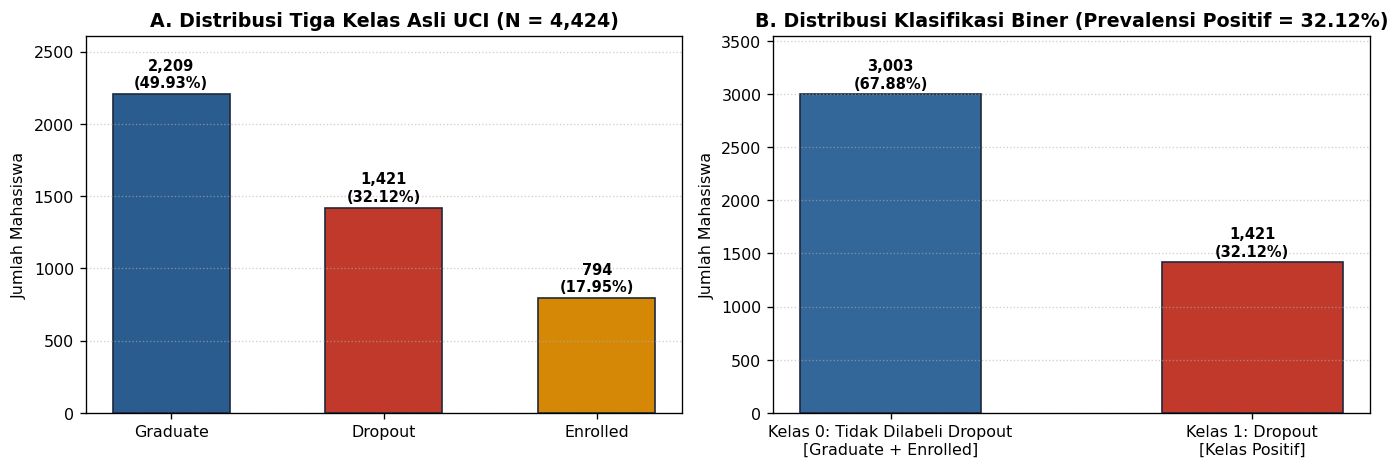

In [20]:
# Bagian 2.5 (Kode): Tabel Pemetaan Tiga Kelas ke Biner dan Visualisasi Distribusi Target
df_uci["obs_id"] = [f"OBS_{i:04d}" for i in range(1, len(df_uci) + 1)]
df_uci["label_dropout"] = (df_uci["Target"] == "Dropout").astype(int)

tabel_pemetaan_target = pd.DataFrame([
    {
        "Label asli": "Dropout",
        "Label penelitian": 1,
        "Jumlah": int((df_uci["Target"] == "Dropout").sum()),
        "Persentase (%)": round((df_uci["Target"] == "Dropout").mean() * 100, 2),
        "Makna": "Mahasiswa dengan status akhir dropout pada endpoint pengamatan",
    },
    {
        "Label asli": "Enrolled",
        "Label penelitian": 0,
        "Jumlah": int((df_uci["Target"] == "Enrolled").sum()),
        "Persentase (%)": round((df_uci["Target"] == "Enrolled").mean() * 100, 2),
        "Makna": "Mahasiswa masih terdaftar pada endpoint pengamatan (right-censored; belum dilabeli Dropout)",
    },
    {
        "Label asli": "Graduate",
        "Label penelitian": 0,
        "Jumlah": int((df_uci["Target"] == "Graduate").sum()),
        "Persentase (%)": round((df_uci["Target"] == "Graduate").mean() * 100, 2),
        "Makna": "Mahasiswa telah menyelesaikan studi pada endpoint pengamatan",
    },
])
display(tabel_pemetaan_target)

n_pos_total = int(df_uci["label_dropout"].sum())
n_neg_total = int((df_uci["label_dropout"] == 0).sum())
print(
    f"Target Biner Kohort Penuh (N={len(df_uci):,}) -> Kelas Positif (Dropout=1): {n_pos_total:,} ({n_pos_total/len(df_uci)*100:.2f}%) | "
    f"Kelas Negatif (Tidak Dilabeli Dropout=0): {n_neg_total:,} ({n_neg_total/len(df_uci)*100:.2f}%)"
)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.0))
urutan_3k = ["Graduate", "Dropout", "Enrolled"]
warna_3k = ["#2b5c8f", "#c0392b", "#d48806"]
cnt_3k = [int((df_uci["Target"] == k).sum()) for k in urutan_3k]
bars1 = axes[0].bar(urutan_3k, cnt_3k, color=warna_3k, edgecolor="#1e293b", width=0.55)
axes[0].set_title(f"A. Distribusi Tiga Kelas Asli UCI (N = {len(df_uci):,})", fontweight="bold")
axes[0].set_ylabel("Jumlah Mahasiswa")
axes[0].set_ylim(0, max(cnt_3k) * 1.18)
axes[0].grid(axis="y", linestyle=":", alpha=0.6)
for b in bars1:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width() / 2, h + 45, f"{h:,}\n({h/len(df_uci)*100:.2f}%)", ha="center", fontsize=8.8, fontweight="bold")

urutan_2k = ["Kelas 0: Tidak Dilabeli Dropout\n[Graduate + Enrolled]", "Kelas 1: Dropout\n[Kelas Positif]"]
cnt_2k = [n_neg_total, n_pos_total]
bars2 = axes[1].bar(urutan_2k, cnt_2k, color=["#336699", "#c0392b"], edgecolor="#1e293b", width=0.50)
axes[1].set_title(f"B. Distribusi Klasifikasi Biner (Prevalensi Positif = {n_pos_total/len(df_uci)*100:.2f}%)", fontweight="bold")
axes[1].set_ylabel("Jumlah Mahasiswa")
axes[1].set_ylim(0, max(cnt_2k) * 1.18)
axes[1].grid(axis="y", linestyle=":", alpha=0.6)
for b in bars2:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width() / 2, h + 55, f"{h:,}\n({h/len(df_uci)*100:.2f}%)", ha="center", fontsize=8.8, fontweight="bold")

plt.tight_layout()
plt.savefig(VIS_DIR / "01_distribusi_target_uci.png", bbox_inches="tight")
plt.show()


---

### 2.6 Penentuan Titik Waktu Prediksi dan Audit Fitur (`Debtor` & `Tuition fees up to date`)

Agar prediksi risiko *dropout* berguna secara praktis untuk intervensi akademik dini, titik waktu prediksi ditetapkan pada **Akhir Semester Pertama** (sebelum perkuliahan Semester Kedua berjalan):
1. **6 Fitur Akademik Semester Kedua Dikeluarkan Mutlak:** Seluruh kolom `Curricular units 2nd sem (...)` belum tersedia pada akhir Semester Pertama sehingga penggunaannya akan menimbulkan *temporal data leakage*.
2. **Evaluasi Kritis terhadap `Debtor` dan `Tuition fees up to date`:**
   * Dokumentasi resmi UCI (#697) dan artikel Realinho et al. (2022) mengelompokkan `Debtor` dan `Tuition fees up to date` sebagai **fitur sosial-ekonomi (*socio-economic features*)**.
   * **Tidak ada bukti sumber resmi yang menyatakan bahwa kedua variabel tersebut terbukti dicatat setelah *dropout* terjadi.** Oleh karena itu, kita tidak mengklaim keduanya sebagai kebocoran pasca-kejadian yang telah terbukti.
   * Demikian pula, **kuatnya hubungan statistik antara status tunggakan biaya kuliah dan label `Dropout` tidak otomatis membuktikan *temporal leakage***, sebab kendala finansial memang dapat menjadi faktor risiko substantif yang mendahului putus studi.
   * Namun, berbeda dari fitur mata kuliah yang dipisahkan secara eksplisit antara `1st sem` dan `2nd sem`, dokumentasi publik tidak mencantumkan *timestamp* per semester mengenai kapan status `Debtor` dan `Tuition fees up to date` dikunci pada pangkalan data institusi.
3. **Spesifikasi 28 Fitur (Konservatif) vs. 30 Fitur (Pembanding):**
   * **Spesifikasi Konservatif (28 Fitur — Konfigurasi Utama):** Mengecualikan `Debtor` dan `Tuition fees up to date` semata-mata karena kehati-hatian atas ketidakpastian *timestamp*, sehingga seluruh 28 fitur yang dipakai memiliki waktu pengamatan yang jelas (saat pendaftaran atau akhir Semester Pertama).
   * **Spesifikasi Pembanding (30 Fitur):** Tetap dievaluasi secara kuantitatif pada Bagian 4.3 dengan mengikutsertakan kedua variabel sosial-ekonomi tersebut sesuai pengelompokan dokumentasi UCI.


In [21]:
# Bagian 2.6 (Kode): Pemeriksaan Hubungan Statistik Variabel Sosial-Ekonomi Keuangan & Tabel Audit 36 Fitur
crosst_tuition = pd.crosstab(df_uci["Tuition fees up to date"], df_uci["Target"], margins=True)
print("=== TABEL SILANG 'Tuition fees up to date' TERHADAP TIGA KELAS TARGET ===")
display(crosst_tuition)

crosst_debtor = pd.crosstab(df_uci["Debtor"], df_uci["Target"], margins=True)
print("=== TABEL SILANG 'Debtor' TERHADAP TIGA KELAS TARGET ===")
display(crosst_debtor)

print(
    "Catatan metodologis: Hubungan statistik yang kuat di atas TIDAK otomatis membuktikan temporal leakage.\n"
    "Kedua fitur dikelompokkan sebagai sosial-ekonomi pada dokumentasi UCI (Realinho et al., 2022), namun tidak\n"
    "memiliki label semester eksplisit. Oleh sebab itu, 28 fitur dipakai sebagai spesifikasi konservatif utama\n"
    "dan 30 fitur tetap diuji sebagai spesifikasi pembanding pada Bagian 4.3."
)

data_audit_36_fitur = [
    ("Marital status", "Status pernikahan mahasiswa (kode kategori 1-6)", "Saat pendaftaran", "Demografi", "Dipakai (Nominal)"),
    ("Application mode", "Jalur/metode pendaftaran masuk (18 kode kategori)", "Saat pendaftaran", "Pendaftaran", "Dipakai (Nominal)"),
    ("Application order", "Urutan pilihan program studi saat mendaftar (0-9)", "Saat pendaftaran", "Pendaftaran", "Dipakai (Numerik Diskrit)"),
    ("Course", "Kode program studi sarjana yang diambil (17 prodi)", "Saat pendaftaran", "Pendaftaran", "Dipakai (Nominal)"),
    ("Daytime/evening attendance", "Jadwal kelas perkuliahan (1=siang, 0=malam)", "Saat pendaftaran", "Pendaftaran", "Dipakai (Biner 0/1)"),
    ("Previous qualification", "Jenjang pendidikan sebelum masuk PT (17 kode)", "Saat pendaftaran", "Akademik Awal", "Dipakai (Nominal)"),
    ("Previous qualification (grade)", "Nilai kualifikasi pendidikan sebelumnya (0-200)", "Saat pendaftaran", "Akademik Awal", "Dipakai (Numerik Kontinu)"),
    ("Nacionality", "Kode kewarganegaraan mahasiswa (21 kode)", "Saat pendaftaran", "Demografi", "Dipakai (Nominal)"),
    ("Mother's qualification", "Tingkat pendidikan ibu (29 kode)", "Saat pendaftaran", "Sosial-Ekonomi", "Dipakai (Nominal)"),
    ("Father's qualification", "Tingkat pendidikan ayah (34 kode)", "Saat pendaftaran", "Sosial-Ekonomi", "Dipakai (Nominal)"),
    ("Mother's occupation", "Kategori pekerjaan ibu menurut ISCO (32 kode)", "Saat pendaftaran", "Sosial-Ekonomi", "Dipakai (Nominal)"),
    ("Father's occupation", "Kategori pekerjaan ayah menurut ISCO (46 kode)", "Saat pendaftaran", "Sosial-Ekonomi", "Dipakai (Nominal)"),
    ("Admission grade", "Nilai seleksi masuk perguruan tinggi (0-200)", "Saat pendaftaran", "Akademik Awal", "Dipakai (Numerik Kontinu)"),
    ("Displaced", "Status mahasiswa perantau/pindah domisili (0/1)", "Saat pendaftaran", "Demografi", "Dipakai (Biner 0/1)"),
    ("Educational special needs", "Kebutuhan khusus pendidikan (0/1)", "Saat pendaftaran", "Demografi", "Dipakai (Biner 0/1)"),
    ("Debtor", "Status debitur menurut dokumentasi UCI (0/1)", "Tanpa timestamp semester eksplisit", "Sosial-Ekonomi (UCI)", "Spesifikasi Pembanding 30 Fitur (Dikeluarkan di 28 Fitur Konservatif)"),
    ("Tuition fees up to date", "Status biaya kuliah menurut dokumentasi UCI (0/1)", "Tanpa timestamp semester eksplisit", "Sosial-Ekonomi (UCI)", "Spesifikasi Pembanding 30 Fitur (Dikeluarkan di 28 Fitur Konservatif)"),
    ("Gender", "Jenis kelamin mahasiswa (1=laki-laki, 0=perempuan)", "Saat pendaftaran", "Demografi", "Dipakai (Biner 0/1)"),
    ("Scholarship holder", "Status penerima beasiswa (0/1)", "Saat pendaftaran / Tahun 1", "Sosial-Ekonomi", "Dipakai (Biner 0/1)"),
    ("Age at enrollment", "Usia mahasiswa saat mendaftar masuk (tahun)", "Saat pendaftaran", "Demografi", "Dipakai (Numerik Diskrit)"),
    ("International", "Status mahasiswa internasional (0/1)", "Saat pendaftaran", "Demografi", "Dipakai (Biner 0/1)"),
    ("Curricular units 1st sem (credited)", "Jumlah MK yang diakui/konversi di Semester 1", "Akhir Semester 1", "Akademik Sem 1", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 1st sem (enrolled)", "Jumlah MK yang diambil di Semester 1", "Akhir Semester 1", "Akademik Sem 1", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 1st sem (evaluations)", "Jumlah evaluasi ujian yang diikuti di Semester 1", "Akhir Semester 1", "Akademik Sem 1", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 1st sem (approved)", "Jumlah MK yang lulus di Semester 1", "Akhir Semester 1", "Akademik Sem 1", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 1st sem (grade)", "Rata-rata nilai MK Semester 1 (skala 0-20)", "Akhir Semester 1", "Akademik Sem 1", "Dipakai (Numerik Kontinu)"),
    ("Curricular units 1st sem (without evaluations)", "Jumlah MK Semester 1 tanpa evaluasi ujian", "Akhir Semester 1", "Akademik Sem 1", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 2nd sem (credited)", "Jumlah MK konversi di Semester 2", "Akhir Semester 2 (Masa depan)", "Akademik Sem 2", "Dikeluarkan (Belum terjadi di Akhir Sem 1)"),
    ("Curricular units 2nd sem (enrolled)", "Jumlah MK diambil di Semester 2", "Akhir Semester 2 (Masa depan)", "Akademik Sem 2", "Dikeluarkan (Belum terjadi di Akhir Sem 1)"),
    ("Curricular units 2nd sem (evaluations)", "Jumlah evaluasi ujian di Semester 2", "Akhir Semester 2 (Masa depan)", "Akademik Sem 2", "Dikeluarkan (Belum terjadi di Akhir Sem 1)"),
    ("Curricular units 2nd sem (approved)", "Jumlah MK lulus di Semester 2", "Akhir Semester 2 (Masa depan)", "Akademik Sem 2", "Dikeluarkan (Belum terjadi di Akhir Sem 1)"),
    ("Curricular units 2nd sem (grade)", "Rata-rata nilai MK Semester 2 (0-20)", "Akhir Semester 2 (Masa depan)", "Akademik Sem 2", "Dikeluarkan (Belum terjadi di Akhir Sem 1)"),
    ("Curricular units 2nd sem (without evaluations)", "Jumlah MK Semester 2 tanpa evaluasi", "Akhir Semester 2 (Masa depan)", "Akademik Sem 2", "Dikeluarkan (Belum terjadi di Akhir Sem 1)"),
    ("Unemployment rate", "Tingkat pengangguran makroekonomi tahun masuk (%)", "Saat pendaftaran", "Makroekonomi", "Dipakai (Numerik Kontinu)"),
    ("Inflation rate", "Tingkat inflasi makroekonomi tahun masuk (%)", "Saat pendaftaran", "Makroekonomi", "Dipakai (Numerik Kontinu)"),
    ("GDP", "Pertumbuhan PDB makroekonomi tahun masuk", "Saat pendaftaran", "Makroekonomi", "Dipakai (Numerik Kontinu)"),
]
df_audit_36 = pd.DataFrame(
    data_audit_36_fitur,
    columns=["Nama Fitur", "Definisi Dokumentasi UCI", "Waktu Ketersediaan", "Kelompok UCI", "Perlakuan pada Studi Ini"],
)
assert len(df_audit_36) == n_fitur_aktual
display(df_audit_36)


=== TABEL SILANG 'Tuition fees up to date' TERHADAP TIGA KELAS TARGET ===


Target,Dropout,Enrolled,Graduate,All
Tuition fees up to date,,,,
0,457,42,29,528
1,964,752,2180,3896
All,1421,794,2209,4424


=== TABEL SILANG 'Debtor' TERHADAP TIGA KELAS TARGET ===


Target,Dropout,Enrolled,Graduate,All
Debtor,,,,
0,1109,704,2108,3921
1,312,90,101,503
All,1421,794,2209,4424


Catatan metodologis: Hubungan statistik yang kuat di atas TIDAK otomatis membuktikan temporal leakage.
Kedua fitur dikelompokkan sebagai sosial-ekonomi pada dokumentasi UCI (Realinho et al., 2022), namun tidak
memiliki label semester eksplisit. Oleh sebab itu, 28 fitur dipakai sebagai spesifikasi konservatif utama
dan 30 fitur tetap diuji sebagai spesifikasi pembanding pada Bagian 4.3.


,Nama Fitur,Definisi Dokumentasi UCI,Waktu Ketersediaan,Kelompok UCI,Perlakuan pada Studi Ini
0,Marital status,Status pernikahan mahasiswa (kode kategori 1-6),Saat pendaftaran,Demografi,Dipakai (Nominal)
1,Application mode,Jalur/metode pendaftaran masuk (18 kode kategori),Saat pendaftaran,Pendaftaran,Dipakai (Nominal)
2,Application order,Urutan pilihan program studi saat mendaftar (0-9),Saat pendaftaran,Pendaftaran,Dipakai (Numerik Diskrit)
3,Course,Kode program studi sarjana yang diambil (17 prodi),Saat pendaftaran,Pendaftaran,Dipakai (Nominal)
4,Daytime/evening attendance,"Jadwal kelas perkuliahan (1=siang, 0=malam)",Saat pendaftaran,Pendaftaran,Dipakai (Biner 0/1)
5,Previous qualification,Jenjang pendidikan sebelum masuk PT (17 kode),Saat pendaftaran,Akademik Awal,Dipakai (Nominal)
6,Previous qualification (grade),Nilai kualifikasi pendidikan sebelumnya (0-200),Saat pendaftaran,Akademik Awal,Dipakai (Numerik Kontinu)
7,Nacionality,Kode kewarganegaraan mahasiswa (21 kode),Saat pendaftaran,Demografi,Dipakai (Nominal)
8,Mother's qualification,Tingkat pendidikan ibu (29 kode),Saat pendaftaran,Sosial-Ekonomi,Dipakai (Nominal)
9,Father's qualification,Tingkat pendidikan ayah (34 kode),Saat pendaftaran,Sosial-Ekonomi,Dipakai (Nominal)


---
## BAGIAN 3 — Landasan Teori Evaluasi Klasifikasi, Kalibrasi Probabilitas, dan Ambang Berbasis Biaya

1. **Confusion Matrix:** Memetakan status aktual $y \in \{0,1\}$ terhadap prediksi $\hat{y}_t = \mathbb{I}(\hat{p} \ge t)$ ke dalam empat sel: **TN** ($y=0,\hat{y}=0$), **FP** ($y=0,\hat{y}=1$), **FN** ($y=1,\hat{y}=0$), dan **TP** ($y=1,\hat{y}=1$).
2. **Precision, Recall, Specificity, dan F1-Score:**
   $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}, \qquad \text{Recall (TPR)} = \frac{\text{TP}}{\text{TP} + \text{FN}}, \qquad \text{Specificity (TNR)} = \frac{\text{TN}}{\text{TN} + \text{FP}}, \qquad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$
3. **ROC-AUC vs. PR-AUC (*Average Precision* vs. *Trapezoidal PR-AUC*):**
   * **ROC-AUC** mengukur peluang pasangan acak positif-negatif diurutkan dengan benar oleh skor model (*baseline* teoretis $= 0{,}50$).
   * **Kurva Precision–Recall** berfokus pada kinerja kelas positif ketika jumlah kelas negatif lebih besar, dengan *baseline* teoretis sebesar **prevalensi kelas positif** $\pi = \frac{P}{P+N}$ (Saito & Rehmsmeier, 2015).
   * **Average Precision (AP)** menghitung jumlahan bertingkat $\sum_n (R_n - R_{n-1})P_n$ tanpa interpolasi miring, sedangkan **Trapezoidal PR-AUC** (`auc(recall, precision)`) menggunakan interpolasi trapesium yang dapat tampak bias naik ketika model mengeluarkan banyak skor probabilitas kembar (*ties*).
4. **Diskriminasi vs. Kalibrasi Probabilitas:**  
   Diskriminasi menilai ketepatan *peringkat skor*, sedangkan kalibrasi menilai apakah nilai probabilitas $\hat{p}_i$ sesuai dengan frekuensi kejadian aktual, diukur dengan **Brier Score** ($\frac{1}{N}\sum_{i=1}^N(\hat{p}_i-y_i)^2$) dan **Expected Calibration Error (ECE)** ($\sum_{b=1}^B \frac{|I_b|}{N}|\bar{p}_b - \bar{y}_b|$), serta diperbaiki menggunakan `CalibratedClassifierCV` (*Platt/Sigmoid* atau *Isotonic*; Niculescu-Mizil & Caruana, 2005).
5. **Matriks Biaya Kesalahan & Kendala Kapasitas:**  
   $$\text{Total Error Cost}(t) = (\text{FP}_t \times C_{\text{FP}}) + (\text{FN}_t \times C_{\text{FN}})$$
   Tanpa kendala kuota dan dengan probabilitas terkalibrasi sempurna, ambang teoretis Bayes berada di sekitar $t^* = \frac{C_{\text{FP}}}{C_{\text{FP}} + C_{\text{FN}}}$ (Elkan, 2001). Apabila terdapat batas kuota tindak lanjut maksimum $K$, maka ambang dipilih untuk meminimalkan biaya dengan syarat $\text{Flagged}(t) = \text{TP}_t + \text{FP}_t \le K$.


---
## BAGIAN 4 — Pembagian Data, Pipeline Preprocessing, dan Eksperimen Sensitivitas

### 4.1 Disiplin Isolasi *Test Set* (*60% Train / 20% Validation / 20% Unseen Test*)
Sesuai instruksi tugas dosen (*"Gunakan probabilitas dari data validasi; data test hanya digunakan untuk evaluasi akhir"*):
* **Training Set (`60%`):** Tempat mempelajari seluruh parameter *preprocessing*, melatih model, `5-Fold Stratified CV`, serta melatih kalibrator probabilitas (`CalibratedClassifierCV`).
* **Validation Set (`20%`):** Tempat mengevaluasi seluruh kandidat model, tiga *Confusion Matrix* (`0,30`, `0,50`, `0,70`), kurva ROC/PR, kalibrasi, matriks biaya, simulasi kapasitas, *Error Analysis*, dan penguncian *threshold* operasional.
* **Test Set (`20%`):** Disimpan terkunci (*strictly blinded*). **Distribusi label kelas pada *Test Set* sengaja tidak dilaporkan maupun disentuh sebelum evaluasi akhir satu kali pada Bagian 7.2.**


In [22]:
# Bagian 4.1 & 4.2 (Kode): Stratified Split (60/20/20) dengan Test Set Blinded & Pipeline ColumnTransformer
df_dev_pool, df_test = train_test_split(
    df_uci, test_size=0.20, stratify=df_uci["Target"], random_state=SEED
)
df_train, df_val = train_test_split(
    df_dev_pool, test_size=0.25, stratify=df_dev_pool["Target"], random_state=SEED
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Distribusi label hanya dilaporkan untuk Train dan Validation; Test Set dikunci tanpa inspeksi label awal
ringkasan_split = [
    {
        "Partisi": "Training Set (60%)",
        "Jumlah Observasi": len(df_train),
        "Proporsi Total (%)": f"{len(df_train)/len(df_uci)*100:.2f}%",
        "Dropout (Kelas 1)": str(int((df_train["label_dropout"] == 1).sum())),
        "Prevalensi Positif": f"{df_train['label_dropout'].mean()*100:.2f}%",
        "Detail Graduate": str(int((df_train["Target"] == "Graduate").sum())),
        "Detail Enrolled": str(int((df_train["Target"] == "Enrolled").sum())),
    },
    {
        "Partisi": "Validation Set (20%)",
        "Jumlah Observasi": len(df_val),
        "Proporsi Total (%)": f"{len(df_val)/len(df_uci)*100:.2f}%",
        "Dropout (Kelas 1)": str(int((df_val["label_dropout"] == 1).sum())),
        "Prevalensi Positif": f"{df_val['label_dropout'].mean()*100:.2f}%",
        "Detail Graduate": str(int((df_val["Target"] == "Graduate").sum())),
        "Detail Enrolled": str(int((df_val["Target"] == "Enrolled").sum())),
    },
    {
        "Partisi": "Test Set (20% - Dikunci untuk Evaluasi Akhir)",
        "Jumlah Observasi": len(df_test),
        "Proporsi Total (%)": f"{len(df_test)/len(df_uci)*100:.2f}%",
        "Dropout (Kelas 1)": "[Dikunci s.d. Bagian 7.2]",
        "Prevalensi Positif": "[Dikunci s.d. Bagian 7.2]",
        "Detail Graduate": "[Dikunci s.d. Bagian 7.2]",
        "Detail Enrolled": "[Dikunci s.d. Bagian 7.2]",
    },
]
df_ringkasan_split = pd.DataFrame(ringkasan_split)
print("=== RINGKASAN PARTISI DATA (DISTRIBUSI LABEL TEST SET DIKUNCI HINGGA EVALUASI AKHIR) ===")
display(df_ringkasan_split)

fitur_numerik = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
]
fitur_biner = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Gender",
    "Scholarship holder",
    "International",
]
fitur_kategorikal_nominal = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]
fitur_konservatif_28 = fitur_numerik + fitur_biner + fitur_kategorikal_nominal
assert len(fitur_konservatif_28) == len(set(fitur_konservatif_28)) == 28
assert set(fitur_konservatif_28).issubset(set(kolom_fitur_semua))


def bangun_preprocessor(num_c, bin_c, nom_c) -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), num_c),
            ("bin", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
            ]), bin_c),
            ("nom", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), nom_c),
        ],
        remainder="drop",
    )


X_train = df_train[fitur_konservatif_28].copy()
y_train = df_train["label_dropout"].to_numpy()

X_val = df_val[fitur_konservatif_28].copy()
y_val = df_val["label_dropout"].to_numpy()

# Test set disiapkan referensinya tanpa dibaca distribusinya sebelum Bagian 7.2
X_test_locked = df_test[fitur_konservatif_28].copy()
y_test_locked = df_test["label_dropout"].to_numpy()

prep_cek = bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal).fit(X_train, y_train)
print(
    f"Pipeline Preprocessing terverifikasi: {X_train.shape[1]} kolom fitur masukan -> "
    f"{prep_cek.transform(X_train).shape[1]} fitur tertransformasi (di-fit murni pada Training Set)."
)


=== RINGKASAN PARTISI DATA (DISTRIBUSI LABEL TEST SET DIKUNCI HINGGA EVALUASI AKHIR) ===


,Partisi,Jumlah Observasi,Proporsi Total (%),Dropout (Kelas 1),Prevalensi Positif,Detail Graduate,Detail Enrolled
0,Training Set (60%),2654,59.99%,853,32.14%,1325,476
1,Validation Set (20%),885,20.00%,284,32.09%,442,159
2,Test Set (20% - Dikunci untuk Evaluasi Akhir),885,20.00%,[Dikunci s.d. Bagian 7.2],[Dikunci s.d. Bagian 7.2],[Dikunci s.d. Bagian 7.2],[Dikunci s.d. Bagian 7.2]


Pipeline Preprocessing terverifikasi: 28 kolom fitur masukan -> 213 fitur tertransformasi (di-fit murni pada Training Set).


### 4.3 Evaluasi *Cross-Validation* di *Training Set*, Sensitivitas 28 vs. 30 Fitur, dan Sensitivitas Eksklusi `Enrolled`
Pada sel berikut kita menjalankan tiga pemeriksaan metodologis pada data pengembangan (*Train/Validation*):
1. **5-Fold Stratified Cross-Validation pada Training Set** untuk membandingkan `DummyClassifier`, `LogisticRegression` (*Native* & *Balanced*), dan `DecisionTreeClassifier` (*Pruned* & *Unpruned*).
2. **Eksperimen Sensitivitas 28 Fitur (Spesifikasi Konservatif) vs. 30 Fitur (Spesifikasi Pembanding dengan `Debtor` & `Tuition fees up to date`) vs. 22 Fitur (Pendaftaran Awal).**
3. **Analisis Sensitivitas `Dropout` vs. `Graduate` (Mengecualikan `Enrolled`)** untuk mengkuantifikasi efek *right-censoring* tanpa menyamakan kedua definisi populasi tersebut.


In [23]:
# Bagian 4.3 (Kode): 5-Fold CV di Train, Uji Sensitivitas 28 vs 30 Fitur, Uji Sensitivitas Dropout vs Graduate, & Pelatihan Model
cv_internal = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def buat_logreg_base(c_val=1.0, cw=None):
    return Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", LogisticRegression(C=c_val, class_weight=cw, max_iter=2000, random_state=SEED)),
    ])


def buat_tree_base(max_d=5, min_leaf=20):
    return Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", DecisionTreeClassifier(max_depth=max_d, min_samples_leaf=min_leaf, random_state=SEED)),
    ])


kandidat_cv_train = {
    "1. Baseline Dummy (Prior)": Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", DummyClassifier(strategy="prior", random_state=SEED)),
    ]),
    "2. Baseline Dummy (Stratified)": Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", DummyClassifier(strategy="stratified", random_state=SEED)),
    ]),
    "3. Logistic Regression Native (C=1.0)": buat_logreg_base(c_val=1.0, cw=None),
    "4. Logistic Regression Native (C=0.5)": buat_logreg_base(c_val=0.5, cw=None),
    "5. Logistic Regression Balanced (C=1.0)": buat_logreg_base(c_val=1.0, cw="balanced"),
    "6. Decision Tree Pruned (depth=5, leaf=20)": buat_tree_base(max_d=5, min_leaf=20),
    "7. Decision Tree Unpruned (depth=None)": buat_tree_base(max_d=None, min_leaf=1),
}

hasil_cv_rows = []
for nama_k, pipe_k in kandidat_cv_train.items():
    skor_cv = cross_validate(
        pipe_k,
        X_train,
        y_train,
        cv=cv_internal,
        scoring={
            "roc_auc": "roc_auc",
            "ap": "average_precision",
            "neg_brier": "neg_brier_score",
            "f1": "f1",
        },
    )
    hasil_cv_rows.append({
        "Model Kandidat (5-Fold CV di Train)": nama_k,
        "CV ROC-AUC (Mean ± SD)": f"{skor_cv['test_roc_auc'].mean():.4f} ± {skor_cv['test_roc_auc'].std():.4f}",
        "CV AP (Mean ± SD)": f"{skor_cv['test_ap'].mean():.4f} ± {skor_cv['test_ap'].std():.4f}",
        "CV Brier Score": round(-skor_cv["test_neg_brier"].mean(), 4),
        "CV F1@0.50": round(skor_cv["test_f1"].mean(), 4),
    })

df_hasil_cv = pd.DataFrame(hasil_cv_rows)
print(f"=== 1. HASIL 5-FOLD STRATIFIED CV PADA TRAINING SET (n = {len(X_train):,}) ===")
display(df_hasil_cv)

# 2. Eksperimen Sensitivitas Spesifikasi Fitur (22 vs 28 Konservatif vs 30 Pembanding) pada Validation Set
fitur_num_enroll = [
    "Application order", "Previous qualification (grade)", "Admission grade",
    "Age at enrollment", "Unemployment rate", "Inflation rate", "GDP",
]
skenario_fitur_cek = [
    ("Spesifikasi Pendaftaran Awal (22 Fitur)", fitur_num_enroll, fitur_biner, fitur_kategorikal_nominal),
    ("Spesifikasi Konservatif Akhir Sem 1 [UTAMA] (28 Fitur)", fitur_numerik, fitur_biner, fitur_kategorikal_nominal),
    ("Spesifikasi Pembanding + Debtor & Tuition Fees (30 Fitur)", fitur_numerik, fitur_biner + ["Debtor", "Tuition fees up to date"], fitur_kategorikal_nominal),
]
baris_sens_fitur = []
for lbl_sf, nc_s, bc_s, mc_s in skenario_fitur_cek:
    kol_s = nc_s + bc_s + mc_s
    pipe_sf = CalibratedClassifierCV(
        estimator=Pipeline([
            ("prep", bangun_preprocessor(nc_s, bc_s, mc_s)),
            ("clf", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)),
        ]),
        method="isotonic",
        cv=cv_internal,
    ).fit(df_train[kol_s], y_train)
    pr_sf = pipe_sf.predict_proba(df_val[kol_s])[:, 1]
    baris_sens_fitur.append({
        "Spesifikasi Fitur (LogReg + Isotonic CV=5)": lbl_sf,
        "Jumlah Fitur": len(kol_s),
        "Val ROC-AUC": round(roc_auc_score(y_val, pr_sf), 4),
        "Val AP": round(average_precision_score(y_val, pr_sf), 4),
        "Val Brier Score": round(brier_score_loss(y_val, pr_sf), 4),
    })
df_sens_fitur = pd.DataFrame(baris_sens_fitur)
print("\n=== 2. SENSITIVITAS SPESIFIKASI 28 FITUR (KONSERVATIF) VS 30 FITUR (PEMBANDING) DI VALIDATION SET ===")
display(df_sens_fitur)

# 3. Pelatihan Seluruh Kandidat Model pada Kohort Utama (28 Fitur Konservatif)
model_terlatih = {
    "Dummy (Prior)": kandidat_cv_train["1. Baseline Dummy (Prior)"].fit(X_train, y_train),
    "Dummy (Stratified)": kandidat_cv_train["2. Baseline Dummy (Stratified)"].fit(X_train, y_train),
    "LogReg (Native, C=1.0)": buat_logreg_base(c_val=1.0, cw=None).fit(X_train, y_train),
    "LogReg (Balanced, C=1.0)": buat_logreg_base(c_val=1.0, cw="balanced").fit(X_train, y_train),
    "LogReg + Platt/Sigmoid (CV=5)": CalibratedClassifierCV(
        estimator=buat_logreg_base(c_val=1.0, cw=None), method="sigmoid", cv=cv_internal
    ).fit(X_train, y_train),
    "LogReg + Isotonic (CV=5)": CalibratedClassifierCV(
        estimator=buat_logreg_base(c_val=1.0, cw=None), method="isotonic", cv=cv_internal
    ).fit(X_train, y_train),
    "Decision Tree Pruned (d=5)": buat_tree_base(max_d=5, min_leaf=20).fit(X_train, y_train),
    "Decision Tree + Platt/Sigmoid": CalibratedClassifierCV(
        estimator=buat_tree_base(max_d=5, min_leaf=20), method="sigmoid", cv=cv_internal
    ).fit(X_train, y_train),
}
proba_val_dict = {nama: mdl.predict_proba(X_val)[:, 1] for nama, mdl in model_terlatih.items()}

# 4. Analisis Sensitivitas Definisi Kelas: Kohort Penuh vs Subset Dropout vs Graduate (Eksklusi Enrolled)
df_sub_dg = df_uci[df_uci["Target"].isin(["Dropout", "Graduate"])].copy()
df_sub_dg["y_dg"] = (df_sub_dg["Target"] == "Dropout").astype(int)
sub_dev, _ = train_test_split(df_sub_dg, test_size=0.20, stratify=df_sub_dg["Target"], random_state=SEED)
sub_tr, sub_va = train_test_split(sub_dev, test_size=0.25, stratify=sub_dev["Target"], random_state=SEED)

mdl_sub_dg = CalibratedClassifierCV(
    estimator=buat_logreg_base(c_val=1.0, cw=None), method="isotonic", cv=cv_internal
).fit(sub_tr[fitur_konservatif_28], sub_tr["y_dg"].to_numpy())
pv_sub_dg = mdl_sub_dg.predict_proba(sub_va[fitur_konservatif_28])[:, 1]
yv_sub_dg = sub_va["y_dg"].to_numpy()

pv_full_iso = proba_val_dict["LogReg + Isotonic (CV=5)"]
pred_full_05 = (pv_full_iso >= 0.50).astype(int)
pred_sub_05 = (pv_sub_dg >= 0.50).astype(int)
tn_f, fp_f, fn_f, tp_f = confusion_matrix(y_val, pred_full_05).ravel()
tn_s, fp_s, fn_s, tp_s = confusion_matrix(yv_sub_dg, pred_sub_05).ravel()

df_sens_enrolled = pd.DataFrame([
    {
        "Definisi Populasi Evaluasi": "Kohort Penuh [UTAMA]: Dropout (1) vs. Enrolled + Graduate (0)",
        "N Total": len(df_uci),
        "n Validasi": len(y_val),
        "Prevalensi Positif": f"{y_val.mean()*100:.2f}%",
        "ROC-AUC": round(roc_auc_score(y_val, pv_full_iso), 4),
        "AP": round(average_precision_score(y_val, pv_full_iso), 4),
        "Brier": round(brier_score_loss(y_val, pv_full_iso), 4),
        "Precision@0.50": round(tp_f / (tp_f + fp_f), 4),
        "Recall@0.50": round(tp_f / (tp_f + fn_f), 4),
        "Specificity@0.50": round(tn_f / (tn_f + fp_f), 4),
    },
    {
        "Definisi Populasi Evaluasi": "Sensitivitas Terminal: Dropout (1) vs. Graduate (0) [Tanpa Enrolled]",
        "N Total": len(df_sub_dg),
        "n Validasi": len(yv_sub_dg),
        "Prevalensi Positif": f"{yv_sub_dg.mean()*100:.2f}%",
        "ROC-AUC": round(roc_auc_score(yv_sub_dg, pv_sub_dg), 4),
        "AP": round(average_precision_score(yv_sub_dg, pv_sub_dg), 4),
        "Brier": round(brier_score_loss(yv_sub_dg, pv_sub_dg), 4),
        "Precision@0.50": round(tp_s / (tp_s + fp_s), 4),
        "Recall@0.50": round(tp_s / (tp_s + fn_s), 4),
        "Specificity@0.50": round(tn_s / (tn_s + fp_s), 4),
    },
])
print("\n=== 3. ANALISIS SENSITIVITAS EKSKLUSI ENROLLED (TIDAK BOLEH DISAMAKAN DENGAN KOHORT PENUH) ===")
display(df_sens_enrolled)


=== 1. HASIL 5-FOLD STRATIFIED CV PADA TRAINING SET (n = 2,654) ===


,Model Kandidat (5-Fold CV di Train),CV ROC-AUC (Mean ± SD),CV AP (Mean ± SD),CV Brier Score,CV F1@0.50
0,1. Baseline Dummy (Prior),0.5000 ± 0.0000,0.3214 ± 0.0008,0.2181,0.0000
1,2. Baseline Dummy (Stratified),0.4893 ± 0.0152,0.3174 ± 0.0065,0.4510,0.3148
2,3. Logistic Regression Native (C=1.0),0.8732 ± 0.0135,0.8114 ± 0.0137,0.1245,0.7018
3,4. Logistic Regression Native (C=0.5),0.8750 ± 0.0138,0.8129 ± 0.0142,0.1236,0.7050
4,5. Logistic Regression Balanced (C=1.0),0.8725 ± 0.0139,0.8086 ± 0.0154,0.1376,0.7129
5,"6. Decision Tree Pruned (depth=5, leaf=20)",0.8335 ± 0.0183,0.7387 ± 0.0196,0.1413,0.6619
6,7. Decision Tree Unpruned (depth=None),0.7177 ± 0.0163,0.5027 ± 0.0205,0.2483,0.6169



=== 2. SENSITIVITAS SPESIFIKASI 28 FITUR (KONSERVATIF) VS 30 FITUR (PEMBANDING) DI VALIDATION SET ===


,Spesifikasi Fitur (LogReg + Isotonic CV=5),Jumlah Fitur,Val ROC-AUC,Val AP,Val Brier Score
0,Spesifikasi Pendaftaran Awal (22 Fitur),22,0.7565,0.6247,0.1763
1,Spesifikasi Konservatif Akhir Sem 1 [UTAMA] (28 Fitur),28,0.8868,0.8408,0.1136
2,Spesifikasi Pembanding + Debtor & Tuition Fees (30 Fitur),30,0.9096,0.8715,0.0987



=== 3. ANALISIS SENSITIVITAS EKSKLUSI ENROLLED (TIDAK BOLEH DISAMAKAN DENGAN KOHORT PENUH) ===


,Definisi Populasi Evaluasi,N Total,n Validasi,Prevalensi Positif,ROC-AUC,AP,Brier,Precision@0.50,Recall@0.50,Specificity@0.50
0,Kohort Penuh [UTAMA]: Dropout (1) vs. Enrolled + Graduate (0),4424,885,32.09%,0.8868,0.8408,0.1136,0.8107,0.6937,0.9235
1,Sensitivitas Terminal: Dropout (1) vs. Graduate (0) [Tanpa Enrolled],3630,726,39.12%,0.9242,0.9127,0.0952,0.8626,0.7958,0.9186


**Interpretasi Ringkas Dua Uji Sensitivitas di Atas:**
1. **28 Fitur Konservatif vs. 30 Fitur Pembanding:** Penambahan `Debtor` dan `Tuition fees up to date` pada `LogReg + Isotonic (CV=5)` meningkatkan `Val ROC-AUC` dari **`0,8868` ke `0,9096`** (`Val AP` dari **`0,8408` ke `0,8715`**, dan menurunkan `Val Brier Score` dari `0,1136` ke `0,0987`). Namun, karena ketiadaan *timestamp* semester eksplisit pada kedua variabel sosial-ekonomi tersebut, penelitian ini menetapkan **28 fitur konservatif** sebagai konfigurasi final agar klaim prediksi akhir Semester Pertama bebas dari ambiguitas waktu pengamatan.
2. **Kohort Penuh vs. Eksklusi `Enrolled`:** Ketika `794` mahasiswa `Enrolled` dikeluarkan, `Val ROC-AUC` tampak naik ke **`0,9242`** (`Val AP = 0,9127`, `Brier = 0,0952`) dan `Precision@0.50` naik dari `0,8107` ke `0,8626`. Kenaikan ini terjadi karena kelompok transisi yang tersensor kanan dihilangkan; kedua angka ini menjawab pertanyaan yang berbeda dan **tidak boleh disamakan**. Seluruh analisis operasional selanjutnya tetap menggunakan kohort penuh ($n_{\text{val}} = 885$).


---
## BAGIAN 5 — Evaluasi Diskriminasi, Kalibrasi Probabilitas, Tiga *Confusion Matrix* (`0,30`, `0,50`, `0,70`), dan Kurva ROC/PR pada *Validation Set*

### 5.1 Pemeriksaan Kualitas Diskriminasi dan Kalibrasi Probabilitas (Langkah 4 & Langkah 6)


In [24]:
# Bagian 5.1 (Kode): ROC-AUC, AP, Trapezoidal PR-AUC, Brier Score, ECE (10-Bin & 5-Bin), dan Tabel Kalibrasi per Bin
def hitung_ece_dan_tabel_bin(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10):
    batas_bin = np.linspace(0.0, 1.0, n_bins + 1)
    ece_total = 0.0
    catatan_bin = []
    n_total = len(y_true)
    for i in range(n_bins):
        b_bawah, b_atas = batas_bin[i], batas_bin[i + 1]
        if i < n_bins - 1:
            mask = (y_prob >= b_bawah) & (y_prob < b_atas)
            label_b = f"[{b_bawah:.1f}, {b_atas:.1f})"
        else:
            mask = (y_prob >= b_bawah) & (y_prob <= b_atas)
            label_b = f"[{b_bawah:.1f}, {b_atas:.1f}]"
        jml = int(np.sum(mask))
        if jml > 0:
            rata_pred = float(np.mean(y_prob[mask]))
            prop_aktual = float(np.mean(y_true[mask]))
            gap = abs(rata_pred - prop_aktual)
            ece_total += (jml / n_total) * gap
            catatan_bin.append({
                "Rentang Bin": label_b,
                "Jumlah Observasi": jml,
                "Rata-rata Prob Prediksi": round(rata_pred, 4),
                "Proporsi Aktual Dropout": round(prop_aktual, 4),
                "Selisih Absolut |Pred - Aktual|": round(gap, 4),
            })
        else:
            catatan_bin.append({
                "Rentang Bin": label_b,
                "Jumlah Observasi": 0,
                "Rata-rata Prob Prediksi": np.nan,
                "Proporsi Aktual Dropout": np.nan,
                "Selisih Absolut |Pred - Aktual|": np.nan,
            })
    return float(ece_total), pd.DataFrame(catatan_bin)


rekap_model_val = []
for nama_m, pv_m in proba_val_dict.items():
    roc_m = roc_auc_score(y_val, pv_m)
    ap_m = average_precision_score(y_val, pv_m)
    prec_curve_m, rec_curve_m, _ = precision_recall_curve(y_val, pv_m)
    trap_pr_m = auc(rec_curve_m, prec_curve_m)
    brier_m = brier_score_loss(y_val, pv_m)
    ece10_m, _ = hitung_ece_dan_tabel_bin(y_val, pv_m, n_bins=10)
    ece5_m, _ = hitung_ece_dan_tabel_bin(y_val, pv_m, n_bins=5)
    pred_def = (pv_m >= 0.50).astype(int)
    rekap_model_val.append({
        "Model": nama_m,
        "ROC-AUC": round(roc_m, 4),
        "Average Precision (AP)": round(ap_m, 4),
        "Trapezoidal PR-AUC": round(trap_pr_m, 4),
        "Selisih (Trap - AP)": round(trap_pr_m - ap_m, 4),
        "Brier Score": round(brier_m, 4),
        "ECE (10-Bin)": round(ece10_m, 4),
        "ECE (5-Bin)": round(ece5_m, 4),
        "F1 (t=0.50)": round(f1_score(y_val, pred_def, zero_division=0), 4),
    })

df_rekap_model_val = pd.DataFrame(rekap_model_val)
print(f"=== TABEL DISKRIMINASI DAN KALIBRASI MODEL PADA VALIDATION SET (n = {len(y_val)}) ===")
display(df_rekap_model_val)

# Tabel detail per-bin (5 bin seragam) untuk membuktikan distorsi class_weight='balanced' vs perbaikan kalibrasi
_, bin5_native = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg (Native, C=1.0)"], n_bins=5)
_, bin5_bal = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg (Balanced, C=1.0)"], n_bins=5)
_, bin5_sig = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg + Platt/Sigmoid (CV=5)"], n_bins=5)
_, bin5_iso = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg + Isotonic (CV=5)"], n_bins=5)

df_bin_ringkas = pd.DataFrame({
    "Bin Probabilitas": bin5_iso["Rentang Bin"],
    "n (Native)": bin5_native["Jumlah Observasi"],
    "Gap Native": bin5_native["Selisih Absolut |Pred - Aktual|"],
    "n (Balanced)": bin5_bal["Jumlah Observasi"],
    "Gap Balanced": bin5_bal["Selisih Absolut |Pred - Aktual|"],
    "n (Platt/Sigmoid)": bin5_sig["Jumlah Observasi"],
    "Gap Platt": bin5_sig["Selisih Absolut |Pred - Aktual|"],
    "n (Isotonic)": bin5_iso["Jumlah Observasi"],
    "Pred Isotonic": bin5_iso["Rata-rata Prob Prediksi"],
    "Aktual Isotonic": bin5_iso["Proporsi Aktual Dropout"],
    "Gap Isotonic": bin5_iso["Selisih Absolut |Pred - Aktual|"],
})
print("\n=== DETAIL KALIBRASI PER BIN (5 BIN SERAGAM) PADA VALIDATION SET ===")
display(df_bin_ringkas)

NAMA_MODEL_FINAL = "LogReg + Isotonic (CV=5)"
model_final_terkunci = model_terlatih[NAMA_MODEL_FINAL]
y_proba_val = proba_val_dict[NAMA_MODEL_FINAL]
print(f"Model utama yang dikunci berdasarkan Validation Set: '{NAMA_MODEL_FINAL}'")


=== TABEL DISKRIMINASI DAN KALIBRASI MODEL PADA VALIDATION SET (n = 885) ===


,Model,ROC-AUC,Average Precision (AP),Trapezoidal PR-AUC,Selisih (Trap - AP),Brier Score,ECE (10-Bin),ECE (5-Bin),F1 (t=0.50)
0,Dummy (Prior),0.5000,0.3209,0.6605,0.3395,0.2179,0.0005,0.0005,0.0000
1,Dummy (Stratified),0.4933,0.3181,0.4191,0.1010,0.4384,0.4384,0.4384,0.3071
2,"LogReg (Native, C=1.0)",0.8852,0.8393,0.8391,-0.0003,0.1142,0.0444,0.0304,0.7571
3,"LogReg (Balanced, C=1.0)",0.8844,0.8367,0.8365,-0.0003,0.1306,0.0975,0.0975,0.7353
4,LogReg + Platt/Sigmoid (CV=5),0.8854,0.8401,0.8398,-0.0003,0.1141,0.0356,0.0218,0.7500
5,LogReg + Isotonic (CV=5),0.8868,0.8408,0.8414,0.0006,0.1136,0.0270,0.0197,0.7476
6,Decision Tree Pruned (d=5),0.8499,0.7765,0.8014,0.0249,0.1284,0.0481,0.0402,0.7382
7,Decision Tree + Platt/Sigmoid,0.8638,0.8163,0.8177,0.0013,0.1230,0.0474,0.0474,0.7324



=== DETAIL KALIBRASI PER BIN (5 BIN SERAGAM) PADA VALIDATION SET ===


,Bin Probabilitas,n (Native),Gap Native,n (Balanced),Gap Balanced,n (Platt/Sigmoid),Gap Platt,n (Isotonic),Pred Isotonic,Aktual Isotonic,Gap Isotonic
0,"[0.0, 0.2)",461,0.0147,344,0.0288,445,0.0002,448,0.0787,0.0848,0.0061
1,"[0.2, 0.4)",137,0.0487,147,0.1381,155,0.0554,150,0.2794,0.2200,0.0594
2,"[0.4, 0.6)",81,0.1035,114,0.2253,88,0.0588,89,0.5017,0.4607,0.0411
3,"[0.6, 0.8)",52,0.0550,92,0.2374,59,0.0013,64,0.6890,0.6875,0.0015
4,"[0.8, 1.0]",154,0.0147,188,0.0455,138,0.0391,134,0.9399,0.9552,0.0153


Model utama yang dikunci berdasarkan Validation Set: 'LogReg + Isotonic (CV=5)'


**Analisis Diskriminasi & Kalibrasi Probabilitas:**
1. **`class_weight='balanced'` Mendistorsi Kalibrasi:** Walaupun `ROC-AUC`-nya tinggi (`0,8844`), pemberian bobot kelas seimbang menggeser probabilitas prediksi terlalu tinggi pada bin menengah `[0.4, 0.6)` dan `[0.6, 0.8)` dengan selisih absolut **`0,2253`** dan **`0,2374`**, sehingga `Brier Score` memburuk ke **`0,1306`** dan `ECE (10-Bin)` membengkak ke **`0,0975`**.
2. **Keunggulan `LogReg + Isotonic (CV=5)`:** Kalibrasi isotonik pada *Training Set* menurunkan galat peluang menjadi **`Brier Score = 0,1136`** dan **`ECE (10-Bin) = 0,0270` (`ECE 5-Bin = 0,0197`)**, sembari mencapai **`ROC-AUC = 0,8868`** dan **`AP = 0,8408`**.
3. **Perbedaan `AP` vs. `Trapezoidal PR-AUC`:** Pada `Dummy (Prior)` yang mengeluarkan skor konstan, `AP = 0,3209` sesuai prevalensi validasi, sedangkan `Trapezoidal PR-AUC = 0,6605` menggelembung akibat interpolasi linier trapesium pada skor kembar.

---

### 5.2 Tiga *Confusion Matrix* (`0,50` Dibandingkan dengan `0,30` dan `0,70`) serta Perbandingan Metrik (Langkah 2 & Langkah 3)


=== TABEL LENGKAP METRIK PADA THRESHOLD 0.30, 0.50, DAN 0.70 (VALIDATION SET, n = 885) ===


,Threshold,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,FPR,FNR,Flagged,Pred_Negatif,Flagged_Pct
0,0.3000,232,111,490,52,0.8158,0.6764,0.8169,0.8153,0.7400,0.1847,0.1831,343,542,38.7600
1,0.5000,197,46,555,87,0.8497,0.8107,0.6937,0.9235,0.7476,0.0765,0.3063,243,642,27.4600
2,0.7000,148,10,591,136,0.8350,0.9367,0.5211,0.9834,0.6697,0.0166,0.4789,158,727,17.8500



=== TABEL PERBANDINGAN PRECISION, RECALL, SPECIFICITY, DAN F1-SCORE ===


,Threshold,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Flagged,Flagged_Pct
0,0.3000,232,111,490,52,0.6764,0.8169,0.8153,0.7400,343,38.7600
1,0.5000,197,46,555,87,0.8107,0.6937,0.9235,0.7476,243,27.4600
2,0.7000,148,10,591,136,0.9367,0.5211,0.9834,0.6697,158,17.8500


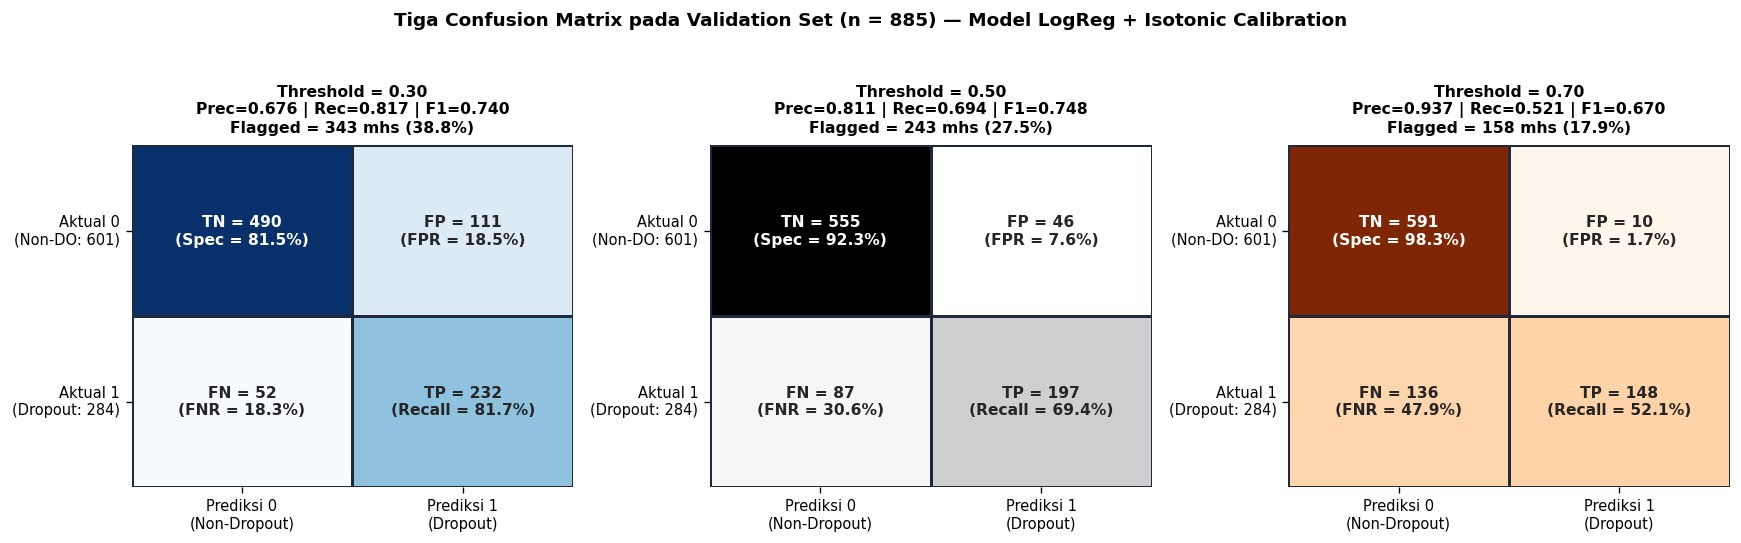

In [25]:
# Bagian 5.2 (Kode): Perhitungan & Visualisasi Tiga Confusion Matrix (0.30, 0.50, 0.70) pada Validation Set
def evaluasi_satu_threshold(y_true: np.ndarray, y_prob: np.ndarray, threshold: float) -> dict:
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    n_obs = len(y_true)
    acc = (tp + tn) / n_obs if n_obs > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = (2.0 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    return {
        "Threshold": round(float(threshold), 6),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "Specificity": round(spec, 4),
        "F1": round(f1, 4),
        "FPR": round(fpr, 4),
        "FNR": round(fnr, 4),
        "Flagged": int(tp + fp),
        "Pred_Negatif": int(tn + fn),
        "Flagged_Pct": round((tp + fp) / n_obs * 100, 2),
    }


threshold_wajib = [0.30, 0.50, 0.70]
hasil_3_threshold = [evaluasi_satu_threshold(y_val, y_proba_val, t) for t in threshold_wajib]
df_3_threshold = pd.DataFrame(hasil_3_threshold)
df_3_threshold.to_csv(TAB_DIR / "01_tabel_tiga_threshold_wajib_validasi.csv", index=False)

print(f"=== TABEL LENGKAP METRIK PADA THRESHOLD 0.30, 0.50, DAN 0.70 (VALIDATION SET, n = {len(y_val)}) ===")
display(df_3_threshold)

print("\n=== TABEL PERBANDINGAN PRECISION, RECALL, SPECIFICITY, DAN F1-SCORE ===")
kolom_perbandingan_utama = ["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct"]
display(df_3_threshold[kolom_perbandingan_utama])

n_neg_val = int((y_val == 0).sum())
n_pos_val = int((y_val == 1).sum())

fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.3))
palet_cm = ["Blues", "Greys", "Oranges"]
for ax, row_t, cmap_name in zip(axes, hasil_3_threshold, palet_cm):
    t_val = row_t["Threshold"]
    cm_mat = np.array([[row_t["TN"], row_t["FP"]], [row_t["FN"], row_t["TP"]]])
    label_sel = np.array([
        [f"TN = {row_t['TN']}\n(Spec = {row_t['Specificity']*100:.1f}%)", f"FP = {row_t['FP']}\n(FPR = {row_t['FPR']*100:.1f}%)"],
        [f"FN = {row_t['FN']}\n(FNR = {row_t['FNR']*100:.1f}%)", f"TP = {row_t['TP']}\n(Recall = {row_t['Recall']*100:.1f}%)"],
    ])
    sns.heatmap(
        cm_mat, annot=label_sel, fmt="", cmap=cmap_name, cbar=False, ax=ax,
        linewidths=1.5, linecolor="#1e293b", annot_kws={"fontsize": 9.3, "fontweight": "bold"},
    )
    ax.set_title(
        f"Threshold = {t_val:.2f}\nPrec={row_t['Precision']:.3f} | Rec={row_t['Recall']:.3f} | F1={row_t['F1']:.3f}\nFlagged = {row_t['Flagged']} mhs ({row_t['Flagged_Pct']:.1f}%)",
        fontsize=9.4, fontweight="bold", pad=8,
    )
    ax.set_xticklabels(["Prediksi 0\n(Non-Dropout)", "Prediksi 1\n(Dropout)"], fontsize=8.8)
    ax.set_yticklabels([f"Aktual 0\n(Non-DO: {n_neg_val})", f"Aktual 1\n(Dropout: {n_pos_val})"], fontsize=8.8, rotation=0)

plt.suptitle(
    f"Tiga Confusion Matrix pada Validation Set (n = {len(y_val)}) — Model LogReg + Isotonic Calibration",
    fontsize=11.1, fontweight="bold", y=1.04,
)
plt.tight_layout()
plt.savefig(VIS_DIR / "02_tiga_confusion_matrix_validasi.png", bbox_inches="tight")
plt.show()


**Analisis Perbandingan `t = 0,50` terhadap `t = 0,30` dan `t = 0,70`:**
* **Titik Acuan Awal `t = 0,50`:** Mendeteksi `TP = 197` dari `284` mahasiswa *dropout* (`Recall = 69,37%`), tetapi melewatkan **`FN = 87` mahasiswa** (`30,63%`), dengan `FP = 46` (`Precision = 81,07%`, `Specificity = 92,35%`, `F1 = 0,7476`, menandai `243` mahasiswa / `27,46%`).
* **Dampak Menurunkan Threshold ke `t = 0,30`:** Cakupan deteksi meningkat menjadi **`TP = 232` (`Recall = 81,69%`, menangkap `35` kasus *dropout* tambahan; `FN` turun ke `52`)**, namun jumlah alarm palsu naik menjadi **`FP = 111`** (`Precision` turun ke `67,64%`, `Specificity` ke `81,53%`, `F1 = 0,7400`) dan total mahasiswa tertandai naik ke **`343` orang (`38,76%`)**.
* **Dampak Menaikkan Threshold ke `t = 0,70`:** `Precision` melonjak ke **`93,67%`** dan `Specificity` ke **`98,34%`** (`FP = 10`), namun `Recall` merosot tajam ke **`52,11%`** karena **`FN = 136` mahasiswa *dropout* gagal terdeteksi** (`F1` turun ke `0,6697`).

---

### 5.3 Visualisasi Kurva ROC, Kurva Precision–Recall, dan *Reliability Diagram* (Langkah 5 & Langkah 6)


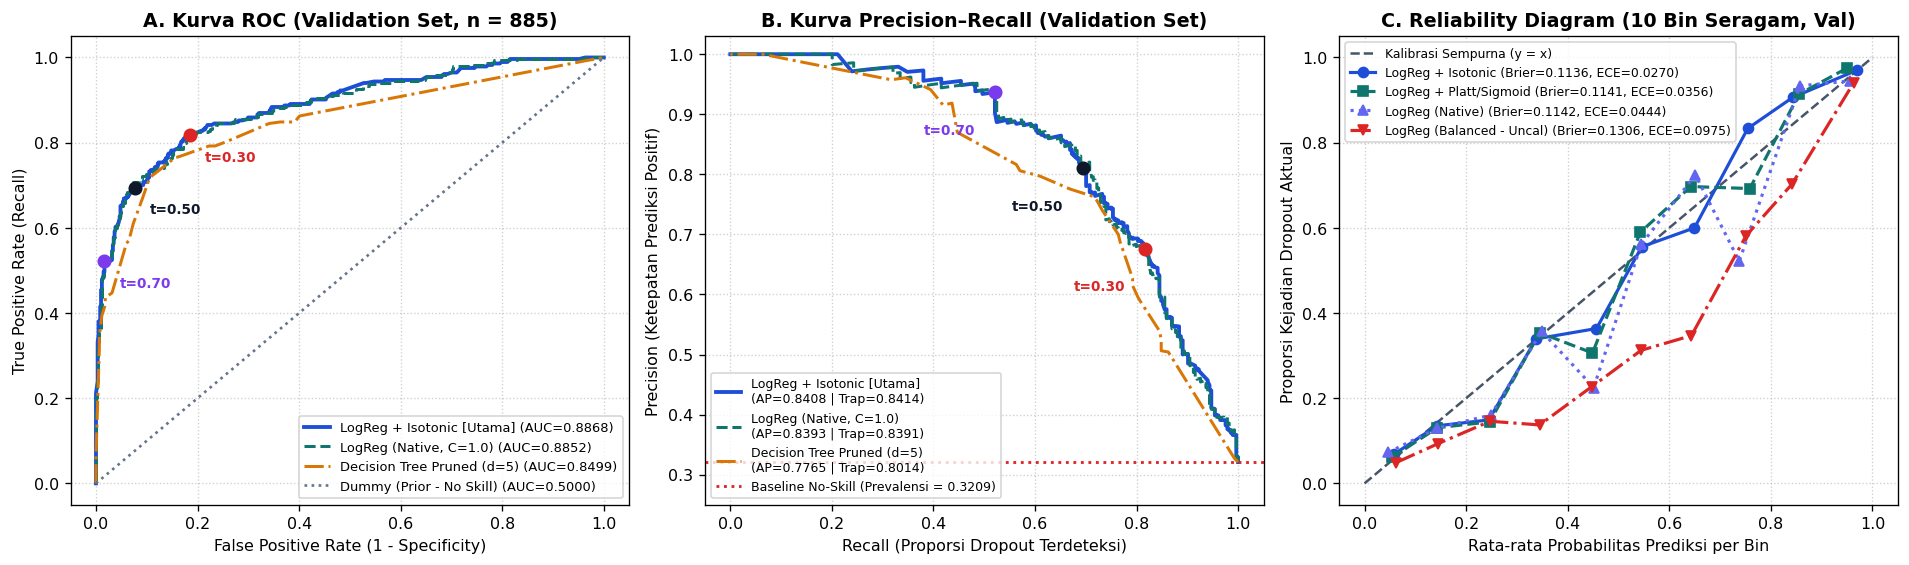

In [26]:
# Bagian 5.3 (Kode): Plot Kurva ROC, Kurva Precision-Recall, dan Reliability Diagram pada Validation Set
prevalensi_pos_val = float(np.mean(y_val))

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.8))

ax_roc = axes[0]
daftar_plot_kurva = [
    ("LogReg + Isotonic [Utama]", proba_val_dict["LogReg + Isotonic (CV=5)"], "#1d4ed8", "-", 2.3),
    ("LogReg (Native, C=1.0)", proba_val_dict["LogReg (Native, C=1.0)"], "#0f766e", "--", 1.8),
    ("Decision Tree Pruned (d=5)", proba_val_dict["Decision Tree Pruned (d=5)"], "#d97706", "-.", 1.8),
    ("Dummy (Prior - No Skill)", proba_val_dict["Dummy (Prior)"], "#64748b", ":", 1.6),
]
for lbl, pr_arr, warna, gaya, tebal in daftar_plot_kurva:
    fpr_c, tpr_c, _ = roc_curve(y_val, pr_arr)
    auc_c = roc_auc_score(y_val, pr_arr)
    ax_roc.plot(fpr_c, tpr_c, color=warna, linestyle=gaya, linewidth=tebal, label=f"{lbl} (AUC={auc_c:.4f})")

for r_t, col_t in zip(hasil_3_threshold, ["#dc2626", "#0f172a", "#7c3aed"]):
    ax_roc.scatter([r_t["FPR"]], [r_t["Recall"]], color=col_t, s=55, zorder=5)
    ax_roc.annotate(
        f"t={r_t['Threshold']:.2f}", (r_t["FPR"], r_t["Recall"]),
        xytext=(r_t["FPR"] + 0.03, r_t["Recall"] - 0.06), fontsize=8.2, fontweight="bold", color=col_t,
    )

ax_roc.set_title(f"A. Kurva ROC (Validation Set, n = {len(y_val)})", fontweight="bold")
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall)")
ax_roc.legend(loc="lower right", fontsize=7.8)
ax_roc.grid(True, linestyle=":", alpha=0.6)

ax_pr = axes[1]
for lbl, pr_arr, warna, gaya, tebal in daftar_plot_kurva[:3]:
    prec_c, rec_c, _ = precision_recall_curve(y_val, pr_arr)
    ap_c = average_precision_score(y_val, pr_arr)
    trap_c = auc(rec_c, prec_c)
    ax_pr.plot(
        rec_c, prec_c, color=warna, linestyle=gaya, linewidth=tebal,
        label=f"{lbl}\n(AP={ap_c:.4f} | Trap={trap_c:.4f})",
    )

ax_pr.axhline(
    prevalensi_pos_val, color="#dc2626", linestyle=":", linewidth=1.7,
    label=f"Baseline No-Skill (Prevalensi = {prevalensi_pos_val:.4f})",
)
for r_t, col_t in zip(hasil_3_threshold, ["#dc2626", "#0f172a", "#7c3aed"]):
    ax_pr.scatter([r_t["Recall"]], [r_t["Precision"]], color=col_t, s=55, zorder=5)
    ax_pr.annotate(
        f"t={r_t['Threshold']:.2f}", (r_t["Recall"], r_t["Precision"]),
        xytext=(r_t["Recall"] - 0.14, r_t["Precision"] - 0.07), fontsize=8.2, fontweight="bold", color=col_t,
    )

ax_pr.set_title("B. Kurva Precision–Recall (Validation Set)", fontweight="bold")
ax_pr.set_xlabel("Recall (Proporsi Dropout Terdeteksi)")
ax_pr.set_ylabel("Precision (Ketepatan Prediksi Positif)")
ax_pr.set_ylim(0.25, 1.03)
ax_pr.legend(loc="lower left", fontsize=7.5)
ax_pr.grid(True, linestyle=":", alpha=0.6)

ax_cal = axes[2]
ax_cal.plot([0, 1], [0, 1], color="#475569", linestyle="--", linewidth=1.5, label="Kalibrasi Sempurna (y = x)")
daftar_kal = [
    ("LogReg + Isotonic", proba_val_dict["LogReg + Isotonic (CV=5)"], "#1d4ed8", "o", "-"),
    ("LogReg + Platt/Sigmoid", proba_val_dict["LogReg + Platt/Sigmoid (CV=5)"], "#0f766e", "s", "--"),
    ("LogReg (Native)", proba_val_dict["LogReg (Native, C=1.0)"], "#6366f1", "^", ":"),
    ("LogReg (Balanced - Uncal)", proba_val_dict["LogReg (Balanced, C=1.0)"], "#dc2626", "v", "-."),
]
for lbl_k, pr_k, col_k, mk_k, ls_k in daftar_kal:
    prob_true_k, prob_pred_k = calibration_curve(y_val, pr_k, n_bins=10, strategy="uniform")
    brier_k = brier_score_loss(y_val, pr_k)
    ece_k, _ = hitung_ece_dan_tabel_bin(y_val, pr_k, n_bins=10)
    ax_cal.plot(
        prob_pred_k, prob_true_k, marker=mk_k, color=col_k, linestyle=ls_k, linewidth=1.9,
        label=f"{lbl_k} (Brier={brier_k:.4f}, ECE={ece_k:.4f})",
    )

ax_cal.set_title("C. Reliability Diagram (10 Bin Seragam, Val)", fontweight="bold")
ax_cal.set_xlabel("Rata-rata Probabilitas Prediksi per Bin")
ax_cal.set_ylabel("Proporsi Kejadian Dropout Aktual")
ax_cal.legend(loc="upper left", fontsize=7.4)
ax_cal.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(VIS_DIR / "03_roc_pr_reliability_validasi.png", bbox_inches="tight")
plt.show()


---
## BAGIAN 6 — Matriks Biaya Kesalahan, Skenario Simulasi Kapasitas Acuan, dan Pemilihan *Threshold* Operasional (Langkah 7 & Langkah 8)

### 6.1 Matriks Biaya *False Positive* dan *False Negative*
Karena dataset UCI #697 tidak memuat besaran biaya moneter konseling maupun kerugian finansial per kasus *dropout*, penalti kesalahan dinormalisasi ke dalam **satuan biaya relatif** ($C_{\text{FP}} = 1$ satuan):

| Kondisi Aktual \ Keputusan Model | Prediksi `0` (`Non-Dropout`) | Prediksi `1` (`Dropout` / Dipanggil) |
| :--- | :--- | :--- |
| **Aktual `0` (`Non-Dropout` pada *endpoint*)** | **TN:** Biaya $= 0$ satuan *(keputusan tepat)* | **FP:** Biaya $= C_{\text{FP}} = 1$ satuan *(alokasi sesi konseling pada non-dropout)* |
| **Aktual `1` (`Dropout`)** | **FN:** Biaya $= C_{\text{FN}} = r \times 1$ satuan *(gagal mendeteksi mahasiswa dropout; skenario acuan $r=4$, uji sensitivitas $r \in \{1,2,4,8\}$)* | **TP:** Biaya $= 0$ satuan *(deteksi dini tepat sasaran)* |

### 6.2 Prevalensi Kelas dan Skenario Simulasi Kapasitas Acuan
Selain biaya kesalahan dan prevalensi kelas positif (`32,12%` pada dataset penuh; `32,09%` pada *Validation Set*), kapasitas layanan konseling diuji menggunakan **skenario simulasi kapasitas tindak lanjut** (`<= 25%`, `<= 30%`, **`<= 35%` sebagai skenario simulasi kapasitas acuan**, `<= 40%`, dan tanpa kendala kuota `<= 100%`).  
**Penegasan penting:** Angka **`35%` adalah skenario simulasi kapasitas acuan untuk pemodelan keputusan, bukan kapasitas empiris institusi asal dataset**. Pencarian *threshold* dilakukan baik pada **grid `0,01`** maupun **pencarian eksak pada seluruh titik probabilitas unik** di *Validation Set* tanpa melakukan *hardcode* nilai sebelum pencarian selesai.


In [27]:
# Bagian 6.1 - 6.3 (Kode): Matriks Biaya 2x2, Pencarian Grid 0.01 & Seluruh Titik Unik (Dengan & Tanpa Kapasitas),
# serta Perbandingan Threshold Eksak vs Pembulatan 0.34 pada Validation Set
df_matriks_biaya_2x2 = pd.DataFrame([
    {
        "Sel Confusion Matrix": "True Negative (TN: y=0, y_hat=0)",
        "Makna Operasional": "Mahasiswa non-dropout tidak dipanggil intervensi",
        "Bobot Biaya (Skenario Acuan 1:4)": 0,
        "Rentang Uji Sensitivitas": "0 satuan",
    },
    {
        "Sel Confusion Matrix": "False Positive (FP: y=0, y_hat=1)",
        "Makna Operasional": "Mahasiswa non-dropout ikut dipanggil konseling (beban kuota & potensi efek right-censoring Enrolled)",
        "Bobot Biaya (Skenario Acuan 1:4)": 1,
        "Rentang Uji Sensitivitas": "C_FP = 1 satuan (acuan normalisasi)",
    },
    {
        "Sel Confusion Matrix": "False Negative (FN: y=1, y_hat=0)",
        "Makna Operasional": "Mahasiswa dropout terlewat tanpa intervensi dini pasca-Semester 1",
        "Bobot Biaya (Skenario Acuan 1:4)": 4,
        "Rentang Uji Sensitivitas": "C_FN in {1, 2, 4, 8} satuan",
    },
    {
        "Sel Confusion Matrix": "True Positive (TP: y=1, y_hat=1)",
        "Makna Operasional": "Mahasiswa berisiko dropout terdeteksi untuk pendampingan dini",
        "Bobot Biaya (Skenario Acuan 1:4)": 0,
        "Rentang Uji Sensitivitas": "0 satuan (beban kuota dihitung terpisah pada Flagged = TP + FP)",
    },
])
print("=== 1. TABEL MATRIKS BIAYA KESALAHAN KLASIFIKASI (2x2) ===")
display(df_matriks_biaya_2x2)

# Ruang kandidat threshold: (a) Grid 0.01 penuh, (b) Seluruh titik probabilitas unik Validation Set
grid_001 = np.round(np.arange(0.01, 1.00, 0.01), 2)
titik_unik_prob = np.sort(np.unique(y_proba_val))


def bangun_tabel_pencarian_threshold(daftar_t, y_true, y_prob):
    baris = []
    for t in daftar_t:
        ev = evaluasi_satu_threshold(y_true, y_prob, float(t))
        fp, fn = ev["FP"], ev["FN"]
        ev["Cost_1_1"] = int(1 * fp + 1 * fn)
        ev["Cost_1_2"] = int(1 * fp + 2 * fn)
        ev["Cost_1_4"] = int(1 * fp + 4 * fn)
        ev["Cost_1_8"] = int(1 * fp + 8 * fn)
        baris.append(ev)
    return pd.DataFrame(baris)


df_grid_val = bangun_tabel_pencarian_threshold(grid_001, y_val, y_proba_val)
df_eksak_val = bangun_tabel_pencarian_threshold(titik_unik_prob, y_val, y_proba_val)

# Sensitivitas lintas 4 rasio biaya tanpa kendala kapasitas (Grid 0.01 vs Eksak Titik Unik)
rekap_sensitivitas_biaya = []
for kol_c, rasio_str, c_fp, c_fn in [
    ("Cost_1_1", "1 : 1 (Setara)", 1, 1),
    ("Cost_1_2", "1 : 2 (Asimetris Ringan)", 1, 2),
    ("Cost_1_4", "1 : 4 (Skenario Biaya Acuan)", 1, 4),
    ("Cost_1_8", "1 : 8 (Proteksi Agresif)", 1, 8),
]:
    r_grid = df_grid_val.sort_values([kol_c, "Flagged"]).iloc[0]
    r_eksak = df_eksak_val.sort_values([kol_c, "Flagged"]).iloc[0]
    rekap_sensitivitas_biaya.append({
        "Rasio Biaya (FP : FN)": rasio_str,
        "Ambang Teoretis Bayes": round(c_fp / (c_fp + c_fn), 4),
        "Biaya t=0.30": int(df_grid_val.loc[df_grid_val["Threshold"] == 0.30, kol_c].iloc[0]),
        "Biaya t=0.50": int(df_grid_val.loc[df_grid_val["Threshold"] == 0.50, kol_c].iloc[0]),
        "Biaya t=0.70": int(df_grid_val.loc[df_grid_val["Threshold"] == 0.70, kol_c].iloc[0]),
        "t* Min (Grid 0.01)": round(float(r_grid["Threshold"]), 2),
        "Biaya Min Grid": int(r_grid[kol_c]),
        "t* Min Eksak (Unik)": round(float(r_eksak["Threshold"]), 4),
        "Biaya Min Eksak": int(r_eksak[kol_c]),
        "Flagged pada t* Eksak": f"{int(r_eksak['Flagged'])} ({r_eksak['Flagged_Pct']:.2f}%)",
    })

df_sensitivitas_biaya = pd.DataFrame(rekap_sensitivitas_biaya)
df_sensitivitas_biaya.to_csv(TAB_DIR / "03_matriks_biaya_2x2_dan_sensitivitas_rasio.csv", index=False)
print(f"\n=== 2. SENSITIVITAS BIAYA TANPA KENDALA KAPASITAS ({len(titik_unik_prob)} TITIK UNIK VS GRID 0.01) ===")
display(df_sensitivitas_biaya)

# Pencarian dengan dan tanpa kendala kapasitas pada seluruh titik unik & grid 0.01
rekap_kapasitas = []
for nama_kap, persen_kap in [
    ("Skenario Simulasi Kapasitas Ketat (<= 25% kohort)", 25),
    ("Skenario Simulasi Kapasitas Terbatas (<= 30% kohort)", 30),
    ("Skenario Simulasi Kapasitas Acuan (<= 35% kohort)", 35),
    ("Skenario Simulasi Kapasitas Longgar (<= 40% kohort)", 40),
    ("Tanpa Kendala Kapasitas (<= 100% kohort)", 100),
]:
    batas_mhs = int(np.floor(len(y_val) * persen_kap / 100.0))
    opt_eksak = df_eksak_val[df_eksak_val["Flagged"] <= batas_mhs].sort_values(["Cost_1_4", "Flagged"]).iloc[0]
    opt_grid = df_grid_val[df_grid_val["Flagged"] <= batas_mhs].sort_values(["Cost_1_4", "Flagged"]).iloc[0]
    rekap_kapasitas.append({
        "Skenario Simulasi Kapasitas": nama_kap,
        "Maks Flagged (Val)": batas_mhs,
        "t* Eksak (Titik Unik)": round(float(opt_eksak["Threshold"]), 4),
        "Biaya Min Eksak (1:4)": int(opt_eksak["Cost_1_4"]),
        "Flagged Eksak": f"{int(opt_eksak['Flagged'])} ({opt_eksak['Flagged_Pct']:.2f}%)",
        "t* Grid 0.01": round(float(opt_grid["Threshold"]), 2),
        "Biaya Min Grid (1:4)": int(opt_grid["Cost_1_4"]),
        "Flagged Grid": f"{int(opt_grid['Flagged'])} ({opt_grid['Flagged_Pct']:.2f}%)",
        "Precision (Eksak)": opt_eksak["Precision"],
        "Recall (Eksak)": opt_eksak["Recall"],
        "Specificity (Eksak)": opt_eksak["Specificity"],
        "F1 (Eksak)": opt_eksak["F1"],
    })

df_simulasi_kapasitas = pd.DataFrame(rekap_kapasitas)
print("\n=== 3. PENCARIAN THRESHOLD DENGAN DAN TANPA KENDALA KAPASITAS (EKSAK TITIK UNIK VS GRID 0.01) ===")
display(df_simulasi_kapasitas)

# Penentuan dinamis threshold skenario simulasi kapasitas acuan 35% (TANPA hardcode sebelum pencarian selesai)
BATAS_MHS_35 = int(np.floor(len(y_val) * 0.35))
baris_min_tanpa_batas_eksak = df_eksak_val.sort_values(["Cost_1_4", "Flagged"]).iloc[0]
baris_min_tanpa_batas_grid = df_grid_val.sort_values(["Cost_1_4", "Flagged"]).iloc[0]

sub_eksak_35 = df_eksak_val[df_eksak_val["Flagged"] <= BATAS_MHS_35]
baris_batas_bawah_eksak_35 = sub_eksak_35.sort_values("Threshold").iloc[0]
baris_opt_eksak_35 = sub_eksak_35.sort_values(["Cost_1_4", "Flagged"]).iloc[0]
baris_opt_grid_35 = df_grid_val[df_grid_val["Flagged"] <= BATAS_MHS_35].sort_values(["Cost_1_4", "Flagged"]).iloc[0]

T_MIN_TANPA_BATAS_GRID = float(baris_min_tanpa_batas_grid["Threshold"])
T_MIN_TANPA_BATAS_EKSAK = float(baris_min_tanpa_batas_eksak["Threshold"])
T_BATAS_BAWAH_EKSAK_35 = float(baris_batas_bawah_eksak_35["Threshold"])
T_OPT_EKSAK_35 = float(baris_opt_eksak_35["Threshold"])
T_OPT_GRID_35 = float(baris_opt_grid_35["Threshold"])

# Perbandingan langsung Threshold Eksak Kapasitas 35% vs Pembulatan Grid 0.34 (dan 0.35)
baris_grid_035 = df_grid_val[df_grid_val["Threshold"] == 0.35].iloc[0]
df_banding_eksak_grid = pd.DataFrame([
    {"Kandidat pada Kapasitas <=35%": "Batas Bawah Eksak Memenuhi <=35% (309 mhs)", **baris_batas_bawah_eksak_35[["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct", "Cost_1_4"]].to_dict()},
    {"Kandidat pada Kapasitas <=35%": "Optimal Biaya Eksak pada <=35% (Titik Unik)", **baris_opt_eksak_35[["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct", "Cost_1_4"]].to_dict()},
    {"Kandidat pada Kapasitas <=35%": "Optimal Biaya Pembulatan Grid 0.01 (Dikunci)", **baris_opt_grid_35[["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct", "Cost_1_4"]].to_dict()},
    {"Kandidat pada Kapasitas <=35%": "Pembulatan ke Atas 2 Desimal (Grid 0.35)", **baris_grid_035[["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct", "Cost_1_4"]].to_dict()},
])
df_banding_eksak_grid.to_csv(TAB_DIR / "04_perbandingan_threshold_eksak_vs_grid_kapasitas.csv", index=False)
print("\n=== 4. PERBANDINGAN THRESHOLD EKSAK KAPASITAS 35% VS NILAI PEMBULATAN 0.34 DAN 0.35 ===")
display(df_banding_eksak_grid)

# Tabel Trade-Off Threshold Lengkap (Luaran Wajib Dosen)
daftar_kandidat_ringkas = sorted(set([0.20, T_MIN_TANPA_BATAS_GRID, 0.30, T_OPT_GRID_35, 0.40, 0.50, 0.60, 0.70]))
df_tradeoff_kandidat = df_grid_val[df_grid_val["Threshold"].isin(daftar_kandidat_ringkas)].copy()
df_tradeoff_kandidat["Status Simulasi Kapasitas <=35%"] = np.where(
    df_tradeoff_kandidat["Flagged"] <= BATAS_MHS_35,
    f"Memenuhi (<={BATAS_MHS_35} mhs)",
    f"Melebihi (>{BATAS_MHS_35} mhs)",
)
kol_tradeoff = ["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Cost_1_4", "Flagged", "Flagged_Pct", "Status Simulasi Kapasitas <=35%"]
df_tradeoff_kandidat = df_tradeoff_kandidat[kol_tradeoff].reset_index(drop=True)
df_tradeoff_kandidat.to_csv(TAB_DIR / "02_tabel_tradeoff_kandidat_threshold_validasi.csv", index=False)
print("\n=== 5. TABEL TRADE-OFF THRESHOLD PADA VALIDATION SET (LUARAN WAJIB) ===")
display(df_tradeoff_kandidat)

# Penguncian threshold operasional setelah pencarian selesai
T_OPERASIONAL_TERKUNCI = T_OPT_GRID_35


=== 1. TABEL MATRIKS BIAYA KESALAHAN KLASIFIKASI (2x2) ===


,Sel Confusion Matrix,Makna Operasional,Bobot Biaya (Skenario Acuan 1:4),Rentang Uji Sensitivitas
0,"True Negative (TN: y=0, y_hat=0)",Mahasiswa non-dropout tidak dipanggil intervensi,0,0 satuan
1,"False Positive (FP: y=0, y_hat=1)",Mahasiswa non-dropout ikut dipanggil konseling (beban kuota & potensi efek right-censoring Enrolled),1,C_FP = 1 satuan (acuan normalisasi)
2,"False Negative (FN: y=1, y_hat=0)",Mahasiswa dropout terlewat tanpa intervensi dini pasca-Semester 1,4,"C_FN in {1, 2, 4, 8} satuan"
3,"True Positive (TP: y=1, y_hat=1)",Mahasiswa berisiko dropout terdeteksi untuk pendampingan dini,0,0 satuan (beban kuota dihitung terpisah pada Flagged = TP + FP)



=== 2. SENSITIVITAS BIAYA TANPA KENDALA KAPASITAS (488 TITIK UNIK VS GRID 0.01) ===


,Rasio Biaya (FP : FN),Ambang Teoretis Bayes,Biaya t=0.30,Biaya t=0.50,Biaya t=0.70,t* Min (Grid 0.01),Biaya Min Grid,t* Min Eksak (Unik),Biaya Min Eksak,Flagged pada t* Eksak
0,1 : 1 (Setara),0.5000,163,133,146,0.5300,127,0.5309,127,223 (25.20%)
1,1 : 2 (Asimetris Ringan),0.3333,215,220,282,0.4400,215,0.3069,212,334 (37.74%)
2,1 : 4 (Skenario Biaya Acuan),0.2000,319,394,554,0.2600,313,0.2682,312,371 (41.92%)
3,1 : 8 (Proteksi Agresif),0.1111,527,742,1098,0.0900,465,0.0946,453,584 (65.99%)



=== 3. PENCARIAN THRESHOLD DENGAN DAN TANPA KENDALA KAPASITAS (EKSAK TITIK UNIK VS GRID 0.01) ===


,Skenario Simulasi Kapasitas,Maks Flagged (Val),t* Eksak (Titik Unik),Biaya Min Eksak (1:4),Flagged Eksak,t* Grid 0.01,Biaya Min Grid (1:4),Flagged Grid,Precision (Eksak),Recall (Eksak),Specificity (Eksak),F1 (Eksak)
0,Skenario Simulasi Kapasitas Ketat (<= 25% kohort),221,0.5452,416,220 (24.86%),0.5500,423,217 (24.52%),0.8545,0.6620,0.9468,0.7460
1,Skenario Simulasi Kapasitas Terbatas (<= 30% kohort),265,0.4599,381,265 (29.94%),0.4600,385,264 (29.83%),0.7698,0.7183,0.8985,0.7432
2,Skenario Simulasi Kapasitas Acuan (<= 35% kohort),309,0.3483,342,306 (34.58%),0.3400,344,308 (34.80%),0.7190,0.7746,0.8569,0.7458
3,Skenario Simulasi Kapasitas Longgar (<= 40% kohort),354,0.2990,317,346 (39.10%),0.3000,319,343 (38.76%),0.6734,0.8204,0.8120,0.7397
4,Tanpa Kendala Kapasitas (<= 100% kohort),885,0.2682,312,371 (41.92%),0.2600,313,372 (42.03%),0.6442,0.8415,0.7804,0.7298



=== 4. PERBANDINGAN THRESHOLD EKSAK KAPASITAS 35% VS NILAI PEMBULATAN 0.34 DAN 0.35 ===


,Kandidat pada Kapasitas <=35%,Threshold,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Flagged,Flagged_Pct,Cost_1_4
0,Batas Bawah Eksak Memenuhi <=35% (309 mhs),0.3389,220.0000,89.0000,512.0000,64.0000,0.7120,0.7746,0.8519,0.7420,309.0000,34.9200,345.0000
1,Optimal Biaya Eksak pada <=35% (Titik Unik),0.3483,220.0000,86.0000,515.0000,64.0000,0.7190,0.7746,0.8569,0.7458,306.0000,34.5800,342.0000
2,Optimal Biaya Pembulatan Grid 0.01 (Dikunci),0.3400,220.0000,88.0000,513.0000,64.0000,0.7143,0.7746,0.8536,0.7432,308.0000,34.8000,344.0000
3,Pembulatan ke Atas 2 Desimal (Grid 0.35),0.3500,219.0000,86.0000,515.0000,65.0000,0.7180,0.7711,0.8569,0.7436,305.0000,34.4600,346.0000



=== 5. TABEL TRADE-OFF THRESHOLD PADA VALIDATION SET (LUARAN WAJIB) ===


,Threshold,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Cost_1_4,Flagged,Flagged_Pct,Status Simulasi Kapasitas <=35%
0,0.2000,246,191,410,38,0.5629,0.8662,0.6822,0.6824,343,437,49.3800,Melebihi (>309 mhs)
1,0.2600,239,133,468,45,0.6425,0.8415,0.7787,0.7287,313,372,42.0300,Melebihi (>309 mhs)
2,0.3000,232,111,490,52,0.6764,0.8169,0.8153,0.7400,319,343,38.7600,Melebihi (>309 mhs)
3,0.3400,220,88,513,64,0.7143,0.7746,0.8536,0.7432,344,308,34.8000,Memenuhi (<=309 mhs)
4,0.4000,213,74,527,71,0.7422,0.7500,0.8769,0.7461,358,287,32.4300,Memenuhi (<=309 mhs)
5,0.5000,197,46,555,87,0.8107,0.6937,0.9235,0.7476,394,243,27.4600,Memenuhi (<=309 mhs)
6,0.6000,172,26,575,112,0.8687,0.6056,0.9567,0.7137,474,198,22.3700,Memenuhi (<=309 mhs)
7,0.7000,148,10,591,136,0.9367,0.5211,0.9834,0.6697,554,158,17.8500,Memenuhi (<=309 mhs)


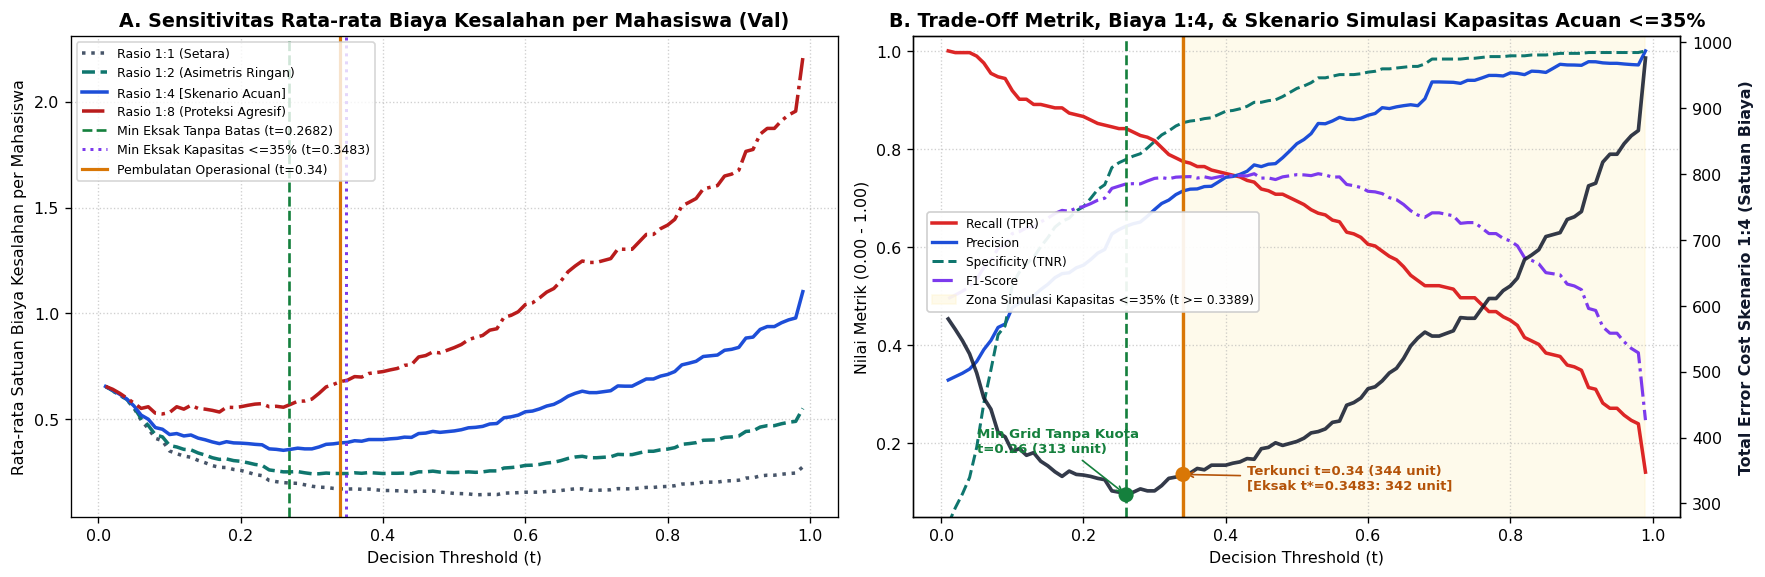

=== KONFIGURASI FINAL YANG DIKUNCI SEBELUM MEMBUKA TEST SET ===
  model_final                                 : LogReg + Isotonic (CV=5)
  spesifikasi_fitur                           : Spesifikasi Konservatif Akhir Semester 1 (28 Fitur)
  skenario_biaya_acuan                        : {'Cost_FP': 1, 'Cost_FN': 4}
  skenario_simulasi_kapasitas_acuan_pct       : 35.0
  threshold_min_tanpa_batas_eksak             : 0.2682
  threshold_min_tanpa_batas_grid              : 0.26
  threshold_batas_bawah_kapasitas_35pct_eksak : 0.3389
  threshold_optimal_kapasitas_35pct_eksak     : 0.3483
  threshold_operasional_pembulatan_grid       : 0.34


In [28]:
# Bagian 6.4 (Kode): Visualisasi Sensitivitas Biaya, Trade-Off Metrik, & Penguncian Konfigurasi Sebelum Test Set
fig, axes = plt.subplots(1, 2, figsize=(14.8, 4.9))

ax1 = axes[0]
for kol_c, lbl_c, col_c, ls_c in [
    ("Cost_1_1", "Rasio 1:1 (Setara)", "#475569", ":"),
    ("Cost_1_2", "Rasio 1:2 (Asimetris Ringan)", "#0f766e", "--"),
    ("Cost_1_4", "Rasio 1:4 [Skenario Acuan]", "#1d4ed8", "-"),
    ("Cost_1_8", "Rasio 1:8 (Proteksi Agresif)", "#b91c1c", "-."),
]:
    ax1.plot(df_grid_val["Threshold"], df_grid_val[kol_c] / len(y_val), color=col_c, linestyle=ls_c, linewidth=2.1, label=lbl_c)

ax1.axvline(T_MIN_TANPA_BATAS_EKSAK, color="#15803d", linestyle="--", linewidth=1.6, label=f"Min Eksak Tanpa Batas (t={T_MIN_TANPA_BATAS_EKSAK:.4f})")
ax1.axvline(T_OPT_EKSAK_35, color="#7c3aed", linestyle=":", linewidth=1.8, label=f"Min Eksak Kapasitas <=35% (t={T_OPT_EKSAK_35:.4f})")
ax1.axvline(T_OPERASIONAL_TERKUNCI, color="#d97706", linestyle="-", linewidth=1.9, label=f"Pembulatan Operasional (t={T_OPERASIONAL_TERKUNCI:.2f})")
ax1.set_title("A. Sensitivitas Rata-rata Biaya Kesalahan per Mahasiswa (Val)", fontweight="bold")
ax1.set_xlabel("Decision Threshold (t)")
ax1.set_ylabel("Rata-rata Satuan Biaya Kesalahan per Mahasiswa")
ax1.legend(loc="upper left", fontsize=7.5)
ax1.grid(True, linestyle=":", alpha=0.6)

ax2 = axes[1]
ax2.plot(df_grid_val["Threshold"], df_grid_val["Recall"], color="#dc2626", linewidth=2.1, label="Recall (TPR)")
ax2.plot(df_grid_val["Threshold"], df_grid_val["Precision"], color="#1d4ed8", linewidth=2.0, label="Precision")
ax2.plot(df_grid_val["Threshold"], df_grid_val["Specificity"], color="#0f766e", linestyle="--", linewidth=1.8, label="Specificity (TNR)")
ax2.plot(df_grid_val["Threshold"], df_grid_val["F1"], color="#7c3aed", linestyle="-.", linewidth=1.9, label="F1-Score")

ax2.axvspan(T_BATAS_BAWAH_EKSAK_35, 0.99, color="#fef3c7", alpha=0.35, label=f"Zona Simulasi Kapasitas <=35% (t >= {T_BATAS_BAWAH_EKSAK_35:.4f})")
ax2.axvline(T_MIN_TANPA_BATAS_GRID, color="#15803d", linestyle="--", linewidth=1.6)
ax2.axvline(T_OPERASIONAL_TERKUNCI, color="#d97706", linestyle="-", linewidth=2.0)

ax2_cost = ax2.twinx()
ax2_cost.plot(df_grid_val["Threshold"], df_grid_val["Cost_1_4"], color="#0f172a", linewidth=2.2, alpha=0.85, label="Total Biaya (1*FP + 4*FN)")
ax2_cost.set_ylabel("Total Error Cost Skenario 1:4 (Satuan Biaya)", fontweight="bold", color="#0f172a")

c_min_grid = int(baris_min_tanpa_batas_grid["Cost_1_4"])
c_opt_grid = int(baris_opt_grid_35["Cost_1_4"])
ax2_cost.scatter([T_MIN_TANPA_BATAS_GRID, T_OPERASIONAL_TERKUNCI], [c_min_grid, c_opt_grid], color=["#15803d", "#d97706"], s=65, zorder=6)
ax2_cost.annotate(
    f"Min Grid Tanpa Kuota\nt={T_MIN_TANPA_BATAS_GRID:.2f} ({c_min_grid} unit)",
    (T_MIN_TANPA_BATAS_GRID, c_min_grid), xytext=(0.05, c_min_grid + 65),
    arrowprops=dict(arrowstyle="->", color="#15803d"), fontsize=8.0, fontweight="bold", color="#15803d",
)
ax2_cost.annotate(
    f"Terkunci t={T_OPERASIONAL_TERKUNCI:.2f} ({c_opt_grid} unit)\n[Eksak t*={T_OPT_EKSAK_35:.4f}: {int(baris_opt_eksak_35['Cost_1_4'])} unit]",
    (T_OPERASIONAL_TERKUNCI, c_opt_grid), xytext=(0.43, c_opt_grid - 22),
    arrowprops=dict(arrowstyle="->", color="#b45309"), fontsize=7.9, fontweight="bold", color="#b45309",
)

ax2.set_title("B. Trade-Off Metrik, Biaya 1:4, & Skenario Simulasi Kapasitas Acuan <=35%", fontweight="bold")
ax2.set_xlabel("Decision Threshold (t)")
ax2.set_ylabel("Nilai Metrik (0.00 - 1.00)")
ax2.set_ylim(0.05, 1.03)
ax2.legend(loc="center left", bbox_to_anchor=(0.01, 0.53), fontsize=7.3, framealpha=0.92)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(VIS_DIR / "04_optimasi_threshold_biaya_kapasitas.png", bbox_inches="tight")
plt.show()

KONFIGURASI_FINAL_TERKUNCI = {
    "model_final": NAMA_MODEL_FINAL,
    "spesifikasi_fitur": "Spesifikasi Konservatif Akhir Semester 1 (28 Fitur)",
    "skenario_biaya_acuan": {"Cost_FP": 1, "Cost_FN": 4},
    "skenario_simulasi_kapasitas_acuan_pct": 35.0,
    "threshold_min_tanpa_batas_eksak": round(T_MIN_TANPA_BATAS_EKSAK, 4),
    "threshold_min_tanpa_batas_grid": round(T_MIN_TANPA_BATAS_GRID, 2),
    "threshold_batas_bawah_kapasitas_35pct_eksak": round(T_BATAS_BAWAH_EKSAK_35, 4),
    "threshold_optimal_kapasitas_35pct_eksak": round(T_OPT_EKSAK_35, 4),
    "threshold_operasional_pembulatan_grid": round(T_OPERASIONAL_TERKUNCI, 2),
}
print("=== KONFIGURASI FINAL YANG DIKUNCI SEBELUM MEMBUKA TEST SET ===")
for k, v in KONFIGURASI_FINAL_TERKUNCI.items():
    print(f"  {k:44s}: {v}")


### 6.5 Rekomendasi *Threshold* Operasional untuk Artikel UAS dan Alasan Pemilihannya
1. **Tanpa Kendala Kapasitas:** Biaya minimum skenario $1:4$ dicapai pada **`t* eksak = 0,2682`** (`312 satuan`) atau **`t grid = 0,26`** (`313 satuan`), tetapi menandai **`41,92%–42,03%` kohort**, jauh di atas prevalensi positif (`32,09%`) dan melampaui skenario simulasi kapasitas acuan `35%`.
2. **Perbandingan Pencarian Eksak vs. Pembulatan `0,34` pada Skenario Simulasi Kapasitas Acuan `<= 35%`:**
   * Ambang terendah yang mulai memenuhi kuota `<= 309` mahasiswa adalah **`t = 0,3389`** (`309` mahasiswa / `34,92%`, `Biaya = 345 satuan`).
   * **Minimum biaya eksak** di dalam wilayah kapasitas `<= 35%` tercapai pada **`t* = 0,3483`** (`306` mahasiswa / `34,58%`, `TP = 220`, `FP = 86`, `FN = 64`, **`Biaya = 342 satuan`**).
   * Apabila dibandingkan dengan pembulatan dua desimal: **`t = 0,34`** memberikan `TP = 220` dan `FN = 64` yang **identik** (`Recall = 77,46%`) dengan hanya selisih `+2 FP` (`88` vs. `86`, `Biaya = 344 satuan`, `Flagged = 34,80%`), sedangkan pembulatan ke atas `t = 0,35` kehilangan `1 TP` sehingga biaya naik ke `346 satuan`.
3. **Keputusan Penguncian:** Kami mengunci **`t_final = 0,34`** sebagai ambang operasional terstandar dua desimal untuk artikel UAS (serta mendokumentasikan titik eksak `t* = 0,3483` secara berdampingan). Dibandingkan ambang bawaan `t = 0,50` (`Biaya = 394 satuan`), `t_final = 0,34` mendeteksi **`23` kasus *dropout* lebih banyak** di *Validation Set* dan menurunkan biaya kesalahan sebesar **`50 satuan` (`-12,69%`)**.


---
## BAGIAN 7 — Analisis Kesalahan Prediksi (*Error Analysis*) dan Evaluasi Akhir Satu Kali pada *Test Set*

### 7.1 Analisis Empat Kasus Kesalahan Prediksi Penting pada *Validation Set* (Langkah 9)


In [29]:
# Bagian 7.1 (Kode): Ekstraksi 4 Kasus Nyata Error Analysis pada Validation Set Menggunakan Threshold Terkunci
kamus_prodi_uci = {
    33: "Biofuel Production Tech.",
    171: "Animation & Multimedia Design",
    8014: "Social Service (Evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising & Marketing Mgmt",
    9773: "Journalism & Communication",
    9853: "Basic Education",
    9991: "Management (Evening)",
}

df_val_analisis = df_val.copy()
df_val_analisis["prob_prediksi"] = np.round(y_proba_val, 4)
df_val_analisis["pred_t030"] = (y_proba_val >= 0.30).astype(int)
df_val_analisis["pred_t_final"] = (y_proba_val >= T_OPERASIONAL_TERKUNCI).astype(int)
df_val_analisis["pred_t050"] = (y_proba_val >= 0.50).astype(int)
df_val_analisis["pred_t070"] = (y_proba_val >= 0.70).astype(int)
df_val_analisis["nama_prodi"] = df_val_analisis["Course"].map(kamus_prodi_uci).fillna("Other")

id_kasus_pilihan = ["OBS_4422", "OBS_2705", "OBS_1631", "OBS_4092"]
df_4_kasus = (
    df_val_analisis[df_val_analisis["obs_id"].isin(id_kasus_pilihan)]
    .set_index("obs_id")
    .loc[id_kasus_pilihan]
    .reset_index()
)

kolom_tampil_err = [
    "obs_id", "Target", "label_dropout", "prob_prediksi",
    "pred_t030", "pred_t_final", "pred_t050", "pred_t070",
    "Course", "nama_prodi", "Age at enrollment", "Gender", "Scholarship holder",
    "Admission grade", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
]
print(f"=== PROFIL AKTUAL EMPAT KASUS ERROR ANALYSIS PADA VALIDATION SET (t_final = {T_OPERASIONAL_TERKUNCI:.2f}) ===")
display(df_4_kasus[kolom_tampil_err])

fp_val_final = df_val_analisis[(df_val_analisis["label_dropout"] == 0) & (df_val_analisis["pred_t_final"] == 1)]
dist_fp_asal = fp_val_final["Target"].value_counts()
print(f"Komposisi {len(fp_val_final)} kasus False Positive pada t_final = {T_OPERASIONAL_TERKUNCI:.2f} di Validation Set:")
print(f"  - Berasal dari label asli 'Enrolled' : {dist_fp_asal.get('Enrolled', 0)} mahasiswa ({dist_fp_asal.get('Enrolled', 0)/len(fp_val_final)*100:.1f}% dari total FP)")
print(f"  - Berasal dari label asli 'Graduate' : {dist_fp_asal.get('Graduate', 0)} mahasiswa ({dist_fp_asal.get('Graduate', 0)/len(fp_val_final)*100:.1f}% dari total FP)")


=== PROFIL AKTUAL EMPAT KASUS ERROR ANALYSIS PADA VALIDATION SET (t_final = 0.34) ===


,obs_id,Target,label_dropout,prob_prediksi,pred_t030,pred_t_final,pred_t050,pred_t070,Course,nama_prodi,Age at enrollment,Gender,Scholarship holder,Admission grade,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade)
0,OBS_4422,Dropout,1,0.0482,0,0,0,0,9500,Nursing,30,0,1,149.5000,7,8,7,14.9125
1,OBS_2705,Enrolled,0,0.9867,1,1,1,1,9670,Advertising & Marketing Mgmt,19,1,0,108.0000,5,10,0,0.0000
2,OBS_1631,Graduate,0,0.7343,1,1,1,1,9130,Equinculture,53,1,0,120.0000,5,9,4,12.2500
3,OBS_4092,Dropout,1,0.4982,1,1,0,0,9991,Management (Evening),29,0,0,135.5000,5,15,2,13.2500


Komposisi 88 kasus False Positive pada t_final = 0.34 di Validation Set:
  - Berasal dari label asli 'Enrolled' : 50 mahasiswa (56.8% dari total FP)
  - Berasal dari label asli 'Graduate' : 38 mahasiswa (43.2% dari total FP)


**Analisis Mendalam (Memisahkan Fakta Data, Interpretasi Fitur, dan Hipotesis):**
1. **`OBS_4422` (*Persistent False Negative*):**
   * *Fakta:* Aktual `Dropout (1)`, probabilitas prediksi `0,0482` (meleset pada `0,30`, `0,34`, `0,50`, dan `0,70`). Mahasiswa `Nursing`, penerima beasiswa, `Admission grade = 149,5`, lulus **`7` dari `7` mata kuliah Semester 1** dengan nilai rata-rata tinggi `14,91`.
   * *Interpretasi:* Seluruh bukti akademik Semester 1 menunjukkan performa prima, sehingga skor rendah memang konsisten secara statistik.
   * *Hipotesis (belum dapat dibuktikan dari dataset):* Putus studi kemungkinan dipicu perubahan kondisi setelah Semester 1 atau faktor non-akademik yang tidak terekam pada 28 fitur awal.
2. **`OBS_2705` (*Persistent False Positive* dari Subkelas `Enrolled`):**
   * *Fakta:* Label biner `0` (`Target` asli = `Enrolled`), probabilitas risiko `0,9867`. Mengambil `5` MK Semester 1, mengikuti `10` evaluasi ujian, tetapi **lulus `0` MK (`grade = 0,0`)**.
   * *Interpretasi:* Kegagalan total di Semester 1 identik dengan profil `Dropout`. Kasus ini beserta fakta bahwa **`50` dari `88` `FP` (`56,8%`) berasal dari subkelas `Enrolled`** mengonfirmasi dampak *right-censoring* pada kelas negatif biner.
   * *Hipotesis (belum dapat dibuktikan dari dataset):* Mahasiswa masih mengulang mata kuliah melampaui durasi studi normal saat periode pengamatan dataset ditutup.
3. **`OBS_1631` (*Persistent False Positive* dari Subkelas `Graduate`):**
   * *Fakta:* Aktual `Graduate (0)`, probabilitas risiko `0,7343`. Mahasiswa laki-laki berusia **`53` tahun** saat mendaftar di `Equinculture`, tanpa beasiswa, `9` evaluasi ujian untuk `5` MK dan lulus `4` MK (`grade = 12,25`).
   * *Interpretasi:* Usia pendaftaran yang ekstrem tinggi (`53` vs. median `20` tahun) dan evaluasi berulang menaikkan *log-odds* linier di atas `0,70`, meskipun kelulusan 4 MK akhirnya cukup mengantar mahasiswa tersebut lulus.
   * *Hipotesis (belum dapat dibuktikan dari dataset):* Terdapat interaksi non-linier ketahanan belajar mahasiswa dewasa pada program studi tertentu.
4. **`OBS_4092` (*Borderline Dropout* yang Diselamatkan oleh `t_final = 0,34`):**
   * *Fakta:* Aktual `Dropout (1)` dengan probabilitas `0,4982`; terlewat sebagai `FN` pada `t = 0,50` dan `0,70`, tetapi tertangkap sebagai `TP` pada `t_final = 0,34` dan `0,30`. Mahasiswa kelas malam `Management (Evening)` yang mengikuti `15` kali ujian untuk `5` MK namun hanya meluluskan `2` MK (`grade = 13,25`).
   * *Interpretasi:* Bukti konkret mengapa penurunan ambang dari `0,50` ke `0,34` bernilai praktis untuk menjangkau mahasiswa zona transisi risiko.

---

### 7.2 Evaluasi Akhir Satu Kali pada *Unseen Test Set*
Setelah model (`LogReg + Isotonic CV=5`), fitur (`28` fitur konservatif), dan *threshold* operasional (`t_final = 0,34`, beserta pendamping eksak `0,3483`) dikunci dari *Training/Validation*, barulah kita mengevaluasi *Test Set*. Nilai `t = 0,50` ditampilkan semata-mata sebagai **evaluasi pembanding acuan yang telah ditentukan sebelumnya (*pre-specified baseline reference*), bukan optimasi *threshold* pada *Test Set***.


Distribusi aktual Test Set dibuka pertama kali pada evaluasi akhir: n=885 (Dropout=284 [32.09%], Non-Dropout=601 [67.91%])

=== HASIL EVALUASI AKHIR SATU KALI PADA TEST SET ===


,Partisi & Skema Evaluasi,Threshold,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Flagged,Flagged_Pct,Error_Cost_1_4,ROC_AUC,AP,Trap_PR_AUC,Brier_Score,ECE_10Bin
0,Validation Set (t_final = 0.34 Terkunci),0.3400,220,88,513,64,0.8282,0.7143,0.7746,0.8536,0.7432,308,34.8000,344,0.8868,0.8408,0.8414,0.1136,0.0270
1,Test Set Final (t_final = 0.34 Terkunci),0.3400,209,78,523,75,0.8271,0.7282,0.7359,0.8702,0.7320,287,32.4300,378,0.8898,0.8217,0.8237,0.1184,0.0234
2,Test Set Pendamping Eksak Val (t* = 0.3483),0.3483,207,76,525,77,0.8271,0.7314,0.7289,0.8735,0.7302,283,31.9800,384,0.8898,0.8217,0.8237,0.1184,0.0234
3,"Test Set Pembanding Pra-Ditetapkan (t = 0.50, Bukan Optimasi)",0.5000,182,45,556,102,0.8339,0.8018,0.6408,0.9251,0.7123,227,25.6500,453,0.8898,0.8217,0.8237,0.1184,0.0234


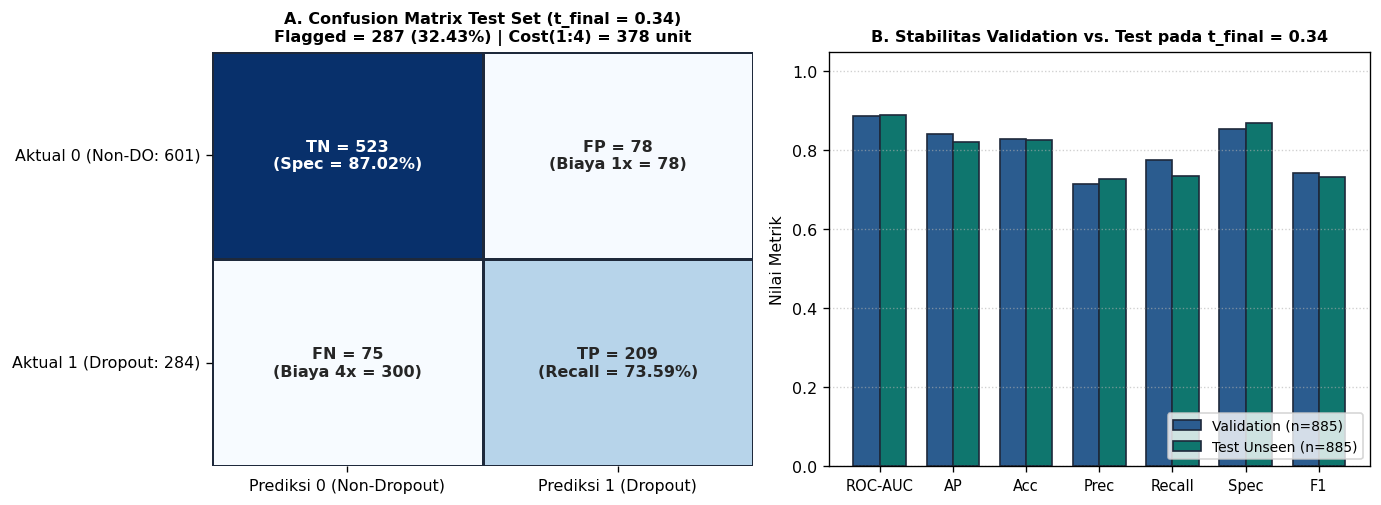

In [30]:
# Bagian 7.2 (Kode): Evaluasi Akhir Satu Kali pada Unseen Test Set dengan Konfigurasi Terkunci
T_FINAL = T_OPERASIONAL_TERKUNCI
T_EKSAK_LOCKED = T_OPT_EKSAK_35
C_FP_FINAL = KONFIGURASI_FINAL_TERKUNCI["skenario_biaya_acuan"]["Cost_FP"]
C_FN_FINAL = KONFIGURASI_FINAL_TERKUNCI["skenario_biaya_acuan"]["Cost_FN"]

y_proba_test = model_final_terkunci.predict_proba(X_test_locked)[:, 1]

n_test_total = len(y_test_locked)
n_test_pos = int(y_test_locked.sum())
n_test_neg = n_test_total - n_test_pos
print(f"Distribusi aktual Test Set dibuka pertama kali pada evaluasi akhir: n={n_test_total} (Dropout={n_test_pos} [{n_test_pos/n_test_total*100:.2f}%], Non-Dropout={n_test_neg} [{n_test_neg/n_test_total*100:.2f}%])")


def ringkasan_evaluasi_lengkap(nama_partisi: str, y_true: np.ndarray, y_prob: np.ndarray, thr: float) -> dict:
    ev = evaluasi_satu_threshold(y_true, y_prob, thr)
    prec_c, rec_c, _ = precision_recall_curve(y_true, y_prob)
    ece_10, _ = hitung_ece_dan_tabel_bin(y_true, y_prob, n_bins=10)
    ev["Partisi & Skema Evaluasi"] = nama_partisi
    ev["ROC_AUC"] = round(roc_auc_score(y_true, y_prob), 4)
    ev["AP"] = round(average_precision_score(y_true, y_prob), 4)
    ev["Trap_PR_AUC"] = round(auc(rec_c, prec_c), 4)
    ev["Brier_Score"] = round(brier_score_loss(y_true, y_prob), 4)
    ev["ECE_10Bin"] = round(ece_10, 4)
    ev["Error_Cost_1_4"] = int(C_FP_FINAL * ev["FP"] + C_FN_FINAL * ev["FN"])
    return ev


hasil_val_final = ringkasan_evaluasi_lengkap(f"Validation Set (t_final = {T_FINAL:.2f} Terkunci)", y_val, y_proba_val, T_FINAL)
hasil_test_final = ringkasan_evaluasi_lengkap(f"Test Set Final (t_final = {T_FINAL:.2f} Terkunci)", y_test_locked, y_proba_test, T_FINAL)
hasil_test_eksak = ringkasan_evaluasi_lengkap(f"Test Set Pendamping Eksak Val (t* = {T_EKSAK_LOCKED:.4f})", y_test_locked, y_proba_test, T_EKSAK_LOCKED)
hasil_test_ref050 = ringkasan_evaluasi_lengkap("Test Set Pembanding Pra-Ditetapkan (t = 0.50, Bukan Optimasi)", y_test_locked, y_proba_test, 0.50)

df_perbandingan_akhir = pd.DataFrame([hasil_val_final, hasil_test_final, hasil_test_eksak, hasil_test_ref050])
kolom_akhir = [
    "Partisi & Skema Evaluasi", "Threshold", "TP", "FP", "TN", "FN",
    "Accuracy", "Precision", "Recall", "Specificity", "F1",
    "Flagged", "Flagged_Pct", "Error_Cost_1_4",
    "ROC_AUC", "AP", "Trap_PR_AUC", "Brier_Score", "ECE_10Bin",
]
df_perbandingan_akhir = df_perbandingan_akhir[kolom_akhir]
df_perbandingan_akhir.to_csv(TAB_DIR / "05_evaluasi_akhir_test_set_terkunci.csv", index=False)

print("\n=== HASIL EVALUASI AKHIR SATU KALI PADA TEST SET ===")
display(df_perbandingan_akhir)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.3))
cm_test_final = np.array([[hasil_test_final["TN"], hasil_test_final["FP"]], [hasil_test_final["FN"], hasil_test_final["TP"]]])
lbl_test_final = np.array([
    [f"TN = {hasil_test_final['TN']}\n(Spec = {hasil_test_final['Specificity']*100:.2f}%)",
     f"FP = {hasil_test_final['FP']}\n(Biaya 1x = {hasil_test_final['FP']})"],
    [f"FN = {hasil_test_final['FN']}\n(Biaya 4x = {C_FN_FINAL*hasil_test_final['FN']})",
     f"TP = {hasil_test_final['TP']}\n(Recall = {hasil_test_final['Recall']*100:.2f}%)"],
])
sns.heatmap(
    cm_test_final, annot=lbl_test_final, fmt="", cmap="Blues", cbar=False, ax=axes[0],
    linewidths=1.6, linecolor="#1e293b", annot_kws={"fontsize": 9.6, "fontweight": "bold"},
)
axes[0].set_title(
    f"A. Confusion Matrix Test Set (t_final = {T_FINAL:.2f})\n"
    f"Flagged = {hasil_test_final['Flagged']} ({hasil_test_final['Flagged_Pct']:.2f}%) | Cost(1:4) = {hasil_test_final['Error_Cost_1_4']} unit",
    fontweight="bold", fontsize=9.6,
)
axes[0].set_xticklabels(["Prediksi 0 (Non-Dropout)", "Prediksi 1 (Dropout)"])
axes[0].set_yticklabels([f"Aktual 0 (Non-DO: {n_test_neg})", f"Aktual 1 (Dropout: {n_test_pos})"], rotation=0)

nama_metrik_bar = ["ROC_AUC", "AP", "Accuracy", "Precision", "Recall", "Specificity", "F1"]
val_bars = [hasil_val_final[m] for m in nama_metrik_bar]
test_bars = [hasil_test_final[m] for m in nama_metrik_bar]
x_pos = np.arange(len(nama_metrik_bar))
w_bar = 0.36
axes[1].bar(x_pos - w_bar / 2, val_bars, width=w_bar, color="#2b5c8f", edgecolor="#1e293b", label=f"Validation (n={len(y_val)})")
axes[1].bar(x_pos + w_bar / 2, test_bars, width=w_bar, color="#0f766e", edgecolor="#1e293b", label=f"Test Unseen (n={n_test_total})")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(["ROC-AUC", "AP", "Acc", "Prec", "Recall", "Spec", "F1"], fontsize=8.8)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Nilai Metrik")
axes[1].set_title(f"B. Stabilitas Validation vs. Test pada t_final = {T_FINAL:.2f}", fontweight="bold", fontsize=9.6)
axes[1].legend(loc="lower right", fontsize=8.3)
axes[1].grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(VIS_DIR / "05_evaluasi_akhir_test_set.png", bbox_inches="tight")
plt.show()


In [31]:
# Bagian 7.3 (Kode): Programmatic Assertions Adaptif terhadap Dimensi Dataset Aktual
assert len(df_train) + len(df_val) + len(df_test) == len(df_uci), "Jumlah baris partisi tidak sama dengan dimensi dataset aktual!"
assert X_train.shape[1] == X_val.shape[1] == X_test_locked.shape[1] == len(fitur_konservatif_28)

for nama_cek, d_cek, y_acuan in [
    ("Validation t=0.30", hasil_3_threshold[0], y_val),
    ("Validation t=0.50", hasil_3_threshold[1], y_val),
    ("Validation t=0.70", hasil_3_threshold[2], y_val),
    ("Validation t_final", hasil_val_final, y_val),
    ("Test t_final", hasil_test_final, y_test_locked),
    ("Test t_eksak", hasil_test_eksak, y_test_locked),
    ("Test ref t=0.50", hasil_test_ref050, y_test_locked),
]:
    tp, fp, tn, fn = d_cek["TP"], d_cek["FP"], d_cek["TN"], d_cek["FN"]
    n_acuan = len(y_acuan)
    n_pos_acuan = int(np.sum(y_acuan == 1))
    assert tp + fp + tn + fn == n_acuan, f"Total CM tidak cocok pada {nama_cek}"
    assert tp + fn == n_pos_acuan, f"Total positif aktual tidak cocok pada {nama_cek}"
    assert d_cek["Flagged"] == tp + fp and d_cek["Pred_Negatif"] == tn + fn
    prec_m = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec_m = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec_m = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1_m = (2 * prec_m * rec_m / (prec_m + rec_m)) if (prec_m + rec_m) > 0 else 0.0
    assert np.isclose(d_cek["Precision"], prec_m, atol=1e-4)
    assert np.isclose(d_cek["Recall"], rec_m, atol=1e-4)
    assert np.isclose(d_cek["Specificity"], spec_m, atol=1e-4)
    assert np.isclose(d_cek["F1"], f1_m, atol=1e-4)

assert np.isclose(prevalensi_pos_val, float(np.mean(y_val)), atol=1e-8)
assert hasil_val_final["Error_Cost_1_4"] == C_FP_FINAL * hasil_val_final["FP"] + C_FN_FINAL * hasil_val_final["FN"]
assert hasil_test_final["Error_Cost_1_4"] == C_FP_FINAL * hasil_test_final["FP"] + C_FN_FINAL * hasil_test_final["FN"]
print("VERIFIKASI KONSISTENSI NUMERIK ADAPTIF LULUS 100%: Seluruh metrik, dimensi, prevalensi, dan biaya konsisten.")


VERIFIKASI KONSISTENSI NUMERIK ADAPTIF LULUS 100%: Seluruh metrik, dimensi, prevalensi, dan biaya konsisten.


---
## BAGIAN 8 — Proposal Singkat Artikel UAS dan Bukti Awal Calon Jurnal SINTA 4

### 8.1 Proposal Singkat Artikel UAS (Langkah 10)
1. **Judul Penelitian:** *Optimasi Ambang Keputusan Sensitif Biaya dan Kalibrasi Probabilitas pada Model Regresi Logistik untuk Prediksi Risiko Putus Studi Mahasiswa Pasca-Semester Pertama*
2. **Pertanyaan Riset (*Research Questions*):**
   * **RQ1:** Seberapa baik daya pisah (`ROC-AUC`, *Average Precision*, dan *Trapezoidal PR-AUC*) model Regresi Logistik dibandingkan *baseline* `DummyClassifier` dan model pembanding `DecisionTreeClassifier` pada spesifikasi konservatif 28 fitur akhir Semester Pertama (serta bagaimana perbandingannya terhadap spesifikasi 30 fitur)?
   * **RQ2:** Bagaimana pengaruh kalibrasi probabilitas eksplisit (*Platt/Sigmoid* dan *Isotonic Regression*) dibandingkan probabilitas bawaan dan `class_weight='balanced'` terhadap *Brier Score* dan `ECE`?
   * **RQ3:** Bagaimana pemilihan *threshold* operasional berdasarkan matriks biaya kesalahan asimetris ($1:1$ s.d. $1:8$), prevalensi kelas, dan skenario simulasi kapasitas tindak lanjut memengaruhi keseimbangan *Precision*, *Recall*, *Specificity*, *F1-Score*, serta total biaya pada *Test Set*?
3. **Dataset & Lisensi:** *Predict Students' Dropout and Academic Success* ($N = 4.424$ mahasiswa, 36 fitur prediktor + kolom `Target`), UCI Machine Learning Repository ID #697 (**DOI Resmi Dataset: `10.24432/C5MC89`**; terpisah dari artikel deskripsi dataset Realinho et al., 2022, **DOI: `10.3390/data7110146`**; Lisensi `CC BY 4.0`).
4. **Baseline:** `DummyClassifier(strategy='prior')` (`ROC-AUC = 0,5000`, `AP Val = 0,3209`), `DummyClassifier(strategy='stratified')`, serta ambang pembanding acuan pra-ditetapkan `t = 0,50`.
5. **Model Utama & Pembanding:** Model utama adalah Pipeline `ColumnTransformer` + `LogisticRegression(C=1.0)` + `CalibratedClassifierCV(method='isotonic', cv=5)`. Model pembanding meliputi `LogisticRegression` (*Native* & *Balanced*), `LogisticRegression + Platt/Sigmoid`, serta `DecisionTreeClassifier` (*Pruned* `max_depth=5, min_samples_leaf=20` & *Unpruned*).
6. **Metrik Evaluasi:** Diskriminasi (`ROC-AUC`, `AP`, `Trapezoidal PR-AUC`), Kalibrasi (`Brier Score`, `ECE` 10-bin & 5-bin, *Reliability Diagram*), Klasifikasi per *Threshold* (`TP, FP, TN, FN, Accuracy, Precision, Recall, Specificity, F1, Flagged`), dan `Total Error Cost`.
7. **Rencana Eksperimen:** (a) Audit data, pemetaan biner dengan uji sensitivitas eksklusi `Enrolled`, dan perbandingan spesifikasi 28 vs. 30 fitur; (b) Pembagian berstrata `60/20/20` dengan *Test Set* terkunci penuh; (c) Evaluasi CV, kalibrasi, tiga *Confusion Matrix* (`0,30`, `0,50`, `0,70`), pencarian *threshold* eksak & grid `0,01`, *Error Analysis*, dan pengujian tunggal *Test Set*; (d) Penyusunan naskah format IMRaD bergaya sitasi IEEE untuk jurnal SINTA 4.

---

### 8.2 Calon Jurnal Ilmiah SINTA 4 dan Pemeriksaan Bukti Verifikasi Awal (Langkah 11)


In [32]:
# Bagian 8.2 (Kode): Tabel Calon Jurnal SINTA 4 Terverifikasi & Pemeriksaan Faktual Berkas Bukti Lokal
folder_bukti = Path("bukti_sinta")
file_ss_komputa = folder_bukti / "komputa_ojs_resmi.png"
file_ss_infotek = folder_bukti / "infotek_ojs_resmi.png"
file_ss_jiko = folder_bukti / "jiko_ojs_resmi.png"

df_verifikasi_jurnal = pd.DataFrame([
    {
        "Calon Jurnal": "KOMPUTA : Jurnal Ilmiah Komputer dan Informatika (UNIKOM) [Kandidat Utama 1]",
        "SINTA ID": "8075",
        "Peringkat": "SINTA 4",
        "ISSN": "p-ISSN 2089-9033 | e-ISSN 2715-7849",
        "Kesesuaian Scope": "Ilmu Komputer, Teknik Informatika, Sistem Informasi, Kecerdasan Buatan, & Machine Learning (Terbit April & Oktober; IEEE)",
        "URL Profil SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/8075",
        "URL OJS Resmi": "https://ojs.unikom.ac.id/index.php/komputa",
        "Bukti Tangkapan Layar Lokal": str(file_ss_komputa) if file_ss_komputa.is_file() else "Belum tersedia berkas tangkapan layar lokal",
    },
    {
        "Calon Jurnal": "Infotek : Jurnal Informatika dan Teknologi (Univ. Hamzanwadi) [Kandidat Utama 2]",
        "SINTA ID": "7721",
        "Peringkat": "SINTA 4",
        "ISSN": "e-ISSN 2614-8773",
        "Kesesuaian Scope": "Teknik Informatika, Data Mining, Rekayasa Perangkat Lunak, & E-Learning (Terbit Januari & Juli)",
        "URL Profil SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/7721",
        "URL OJS Resmi": "https://e-journal.hamzanwadi.ac.id/index.php/infotek",
        "Bukti Tangkapan Layar Lokal": str(file_ss_infotek) if file_ss_infotek.is_file() else "Belum tersedia berkas tangkapan layar lokal",
    },
    {
        "Calon Jurnal": "JIKO (Jurnal Informatika dan Komputer) — UTDI Yogyakarta [Kandidat Cadangan]",
        "SINTA ID": "103",
        "Peringkat": "SINTA 4",
        "ISSN": "p-ISSN 2477-4413 | e-ISSN 2477-3964",
        "Kesesuaian Scope": "Informatika & Komputer: Machine Learning, Klasifikasi, & Sistem Pendukung Keputusan (Terbit Feb, Juni, Okt; IEEE)",
        "URL Profil SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/103",
        "URL OJS Resmi": "https://ejournal.utdi.ac.id/index.php/jiko",
        "Bukti Tangkapan Layar Lokal": str(file_ss_jiko) if file_ss_jiko.is_file() else "Belum tersedia berkas lokal (OJS memblokir akses otomatis HTTP 403)",
    },
])
df_verifikasi_jurnal.to_csv(TAB_DIR / "06_verifikasi_calon_jurnal_sinta4.csv", index=False)

print("=== TABEL CALON JURNAL TARGET SINTA 4 BERDASARKAN PROFIL RESMI ===")
display(df_verifikasi_jurnal)

if folder_bukti.is_dir():
    print(f"Berkas nyata yang tersedia di dalam folder '{folder_bukti}/': {sorted(p.name for p in folder_bukti.iterdir())}")


=== TABEL CALON JURNAL TARGET SINTA 4 BERDASARKAN PROFIL RESMI ===


,Calon Jurnal,SINTA ID,Peringkat,ISSN,Kesesuaian Scope,URL Profil SINTA,URL OJS Resmi,Bukti Tangkapan Layar Lokal
0,KOMPUTA : Jurnal Ilmiah Komputer dan Informatika (UNIKOM) [Kandidat Utama 1],8075,SINTA 4,p-ISSN 2089-9033 | e-ISSN 2715-7849,"Ilmu Komputer, Teknik Informatika, Sistem Informasi, Kecerdasan Buatan, & Machine Learning (Terbit April & Oktober; ...",https://sinta.kemdiktisaintek.go.id/journals/profile/8075,https://ojs.unikom.ac.id/index.php/komputa,bukti_sinta\komputa_ojs_resmi.png
1,Infotek : Jurnal Informatika dan Teknologi (Univ. Hamzanwadi) [Kandidat Utama 2],7721,SINTA 4,e-ISSN 2614-8773,"Teknik Informatika, Data Mining, Rekayasa Perangkat Lunak, & E-Learning (Terbit Januari & Juli)",https://sinta.kemdiktisaintek.go.id/journals/profile/7721,https://e-journal.hamzanwadi.ac.id/index.php/infotek,bukti_sinta\infotek_ojs_resmi.png
2,JIKO (Jurnal Informatika dan Komputer) — UTDI Yogyakarta [Kandidat Cadangan],103,SINTA 4,p-ISSN 2477-4413 | e-ISSN 2477-3964,"Informatika & Komputer: Machine Learning, Klasifikasi, & Sistem Pendukung Keputusan (Terbit Feb, Juni, Okt; IEEE)",https://sinta.kemdiktisaintek.go.id/journals/profile/103,https://ejournal.utdi.ac.id/index.php/jiko,Belum tersedia berkas lokal (OJS memblokir akses otomatis HTTP 403)


Berkas nyata yang tersedia di dalam folder 'bukti_sinta/': ['VERIFIKASI_JURNAL_SINTA4.md', 'infotek_ojs_resmi.png', 'komputa_ojs_resmi.png']


---
## BAGIAN 9 — Jawaban Lima Latihan Analitis, Kesimpulan, Keterbatasan, dan Daftar Pustaka

### 9.1 Jawaban Lima Latihan Analitis Wajib Dosen

#### 1. Kapan *Recall* perlu diprioritaskan?
*Recall* ($\frac{\text{TP}}{\text{TP} + \text{FN}}$) perlu diprioritaskan ketika **kerugian akibat gagal mendeteksi satu kasus positif aktual (*False Negative* / `FN`) jauh lebih besar dibandingkan biaya menindaklanjuti satu alarm palsu (*False Positive* / `FP`)**. Dalam studi prediksi risiko *dropout* mahasiswa, melewatkan mahasiswa berisiko (`FN`) menghilangkan kesempatan intervensi akademik dini hingga mahasiswa benar-benar putus studi, sedangkan satu `FP` hanya membutuhkan satu sesi konsultasi pembimbingan tambahan. Prinsip yang sama berlaku pada penapisan awal penyakit serius dan deteksi transaksi penipuan (*fraud*).

#### 2. Hitung *Precision* jika $\text{TP} = 40$ dan $\text{FP} = 10$.
$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}} = \frac{40}{40 + 10} = \frac{40}{50} = 0{,}80 \text{ atau } 80\%$$
**Interpretasi:** Dari `50` observasi yang diprediksi positif oleh model (`40 TP + 10 FP`), sebanyak `40` observasi (`80%`) benar-benar positif aktual, sedangkan `10` observasi (`20%`) merupakan prediksi positif palsu (`FP`).

#### 3. Mengapa *Specificity* tetap penting?
*Specificity* ($\frac{\text{TN}}{\text{TN} + \text{FP}}$) mengukur proporsi kelas negatif yang berhasil dikenali dengan benar sebagai negatif. Walaupun kita memprioritaskan *Recall*, mengabaikan *Specificity* (misalnya menurunkan *threshold* mendekati `0` agar semua orang diprediksi positif) akan membuat *Specificity* jatuh mendekati `0%` dan memicu lonjakan besar `FP`—terutama ketika kelas negatif merupakan mayoritas (`67,88%` pada dataset ini). Akibatnya, kapasitas konselor/dosen wali akan lumpuh oleh panggilan salah sasaran, total biaya kesalahan kembali membengkak, dan pengguna kehilangan kepercayaan akibat kelelahan alarm (*alarm fatigue*).

#### 4. Apa *baseline* PR-AUC?
Berbeda dengan `ROC-AUC` yang memiliki *baseline* konstan `0,50`, **baseline teoretis dari kurva Precision–Recall (`PR-AUC` / *Average Precision*) adalah prevalensi (proporsi) kelas positif pada data evaluasi**:
$$\text{Baseline PR-AUC} = \frac{P}{P + N}$$
Pengklasifikasi tanpa daya pisah (*no-skill classifier*) yang menebak acak atau memberi probabilitas konstan akan memperoleh *Precision* sebesar $\frac{P}{P+N}$ di sepanjang sumbu *Recall* (pada *Validation Set* kita sebesar $\frac{284}{885} = 0{,}3209$, jauh di bawah capaian `AP = 0,8408` model utama).

#### 5. Jelaskan perbedaan diskriminasi dan kalibrasi!
* **Diskriminasi (*Discrimination*):** Kemampuan model **memisahkan dan mengurutkan peringkat skor** antara kelas positif dan negatif sehingga kasus positif konsisten memperoleh skor lebih tinggi daripada kasus negatif (diukur dengan `ROC-AUC` dan `AP`; tidak berubah bila seluruh skor ditransformasi monoton naik).
* **Kalibrasi (*Calibration*):** Kesesuaian **besaran numerik probabilitas prediksi $\hat{p}$** terhadap frekuensi kejadian aktual di lapangan—misalnya dari kelompok mahasiswa dengan prediksi risiko `0,35`, sekitar `35%` benar-benar mengalami `Dropout` (diukur dengan *Brier Score*, `ECE`, dan *Reliability Diagram*). Sebagaimana terbukti pada Bagian 5.1, `LogReg (Balanced)` memiliki diskriminasi tinggi (`ROC-AUC = 0,8844`) tetapi kalibrasi buruk (`ECE = 0,0975`), sedangkan `LogReg + Isotonic` unggul pada diskriminasi (`ROC-AUC = 0,8868`) **sekaligus** terkalibrasi baik (`ECE = 0,0270`).

---

### 9.2 Kesimpulan Akhir dan Keterbatasan Metodologis
1. **Kesimpulan Utama:** Pada spesifikasi konservatif 28 fitur akhir Semester Pertama dataset UCI #697 ($N = 4.424$), model `LogReg + Isotonic (CV=5)` memberikan kombinasi diskriminasi dan kalibrasi terbaik di *Validation Set* (`ROC-AUC = 0,8868`, `AP = 0,8408`, `Brier = 0,1136`, `ECE 10-Bin = 0,0270`). Berdasarkan skenario biaya acuan $1:4$ dan skenario simulasi kapasitas acuan `<= 35%`, titik optimal eksak di *Validation Set* adalah `t* = 0,3483` (`342 satuan`) dan ambang operasional pembulatan grid yang dikunci adalah **`t_final = 0,34`** (`344 satuan`). Evaluasi satu kali pada *Unseen Test Set* ($n = 885$) mengonfirmasi generalisasi yang stabil (`ROC-AUC = 0,8898`, `AP = 0,8217`, `Brier = 0,1184`, `ECE = 0,0234`, `Precision = 72,82%`, `Recall = 73,59%`, `Specificity = 87,02%`, `F1 = 0,7320`, `Flagged = 32,43%`, `Biaya = 378 satuan` vs. `453 satuan` pada acuan `t = 0,50`).
2. **Bagian yang Belum Dapat Dibuktikan dari Data Tersedia (*Keterbatasan Jujur*):**
   * *Timestamp* pencatatan internal `Debtor` dan `Tuition fees up to date` di SIAKAD institusi asal tidak tersedia per semester.
   * Status kelanjutan studi mahasiswa `Enrolled` pasca-periode pengamatan dataset tidak diketahui (*right-censoring*).
   * Biaya moneter riil konseling, kapasitas empiris konselor institusi asal, serta persentase keberhasilan intervensi mencegah *dropout* tidak tersedia dalam dataset publik dan oleh karenanya dimodelkan sebagai skenario eksplisit.

---

### 9.3 Daftar Pustaka
1. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
2. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting Student Dropout and Academic Success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146
3. Saito, T., & Rehmsmeier, M. (2015). The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets. *PLOS ONE*, 10(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
4. Elkan, C. (2001). The Foundations of Cost-Sensitive Learning. *Proceedings of the Seventeenth International Joint Conference on Artificial Intelligence (IJCAI'01)*, 973–978.
5. Niculescu-Mizil, A., & Caruana, R. (2005). Predicting Good Probabilities With Supervised Learning. *Proceedings of the 22nd International Conference on Machine Learning (ICML)*, 625–632. https://doi.org/10.1145/1102351.1102430
6. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, E. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
